# Import Data and Modules

In [ ]:
# read the dataset from google drive
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

Mounted at /content/drive


In [ ]:
!pip install --quiet nltk gensim wordcloud pyLDAvis contractions unidecode spacy autocorrect
!python -m spacy download en_core_web_sm

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 39.6 MB/s eta 0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.


In [ ]:
# import data from google drive

# Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
import calendar

barbie_trailer = pd.read_csv("/content/drive/My Drive/Natural Language Processing/Trailer Reviews/barbie.csv") #reviews from youtube trailer
oppen_trailer = pd.read_csv("/content/drive/My Drive/Natural Language Processing/Trailer Reviews/oppenheimer.csv") #reviews from youtube trailer
barbieheimer = pd.read_csv("/content/drive/My Drive/Natural Language Processing/Trailer Reviews/barbieheimer.csv") #reviews from youtube
barbie_imdb = pd.read_csv("/content/drive/My Drive/Natural Language Processing/IMDB Reviews/barbie_post.csv") #reviews from IMDB
oppen_imdb = pd.read_csv("/content/drive/My Drive/Natural Language Processing/IMDB Reviews/oppenheimer_post.csv") #reviews from IMDB
barbie_imdb2 = pd.read_csv("/content/drive/My Drive/Natural Language Processing/IMDB Reviews/barbie_imdb.csv") #reviews from IMDB
oppen_imdb2 = pd.read_csv("/content/drive/My Drive/Natural Language Processing/IMDB Reviews/Oppen_imdb.csv") #reviews from IMDB

# Sentiment Analysis Variables
barbie_trailer_SA = pd.read_csv("/content/drive/MyDrive/Natural Language Processing/The Lexical Suite Outputs/barbie_trailer_comments (LS output).csv")
oppen_trailer_SA = pd.read_csv("/content/drive/MyDrive/Natural Language Processing/The Lexical Suite Outputs/oppenheimer_trailer_comments (LS output).csv")
barbieheimer_SA = pd.read_csv("/content/drive/MyDrive/Natural Language Processing/The Lexical Suite Outputs/barbieheimer_trailer_comments (LS output).csv")
barbie_imdb_SA = pd.read_csv("/content/drive/MyDrive/Natural Language Processing/The Lexical Suite Outputs/barbie_imdb_clean (LS output).csv")
oppen_imdb_SA = pd.read_csv("/content/drive/MyDrive/Natural Language Processing/The Lexical Suite Outputs/oppen_imdb_clean (LS output).csv")

In [ ]:

import nltk
import spacy
import string
import gensim
import pyLDAvis
import pyLDAvis.gensim_models as gensimvis
import contractions
import unicodedata
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from wordcloud import WordCloud
from autocorrect import Speller
from gensim import corpora, models

# Ensure all necessary NLTK resources are downloaded
nltk.download('punkt')
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')
nltk.download('punkt_tab')

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


True

/usr/local/lib/python3.11/dist-packages/ipykernel/ipkernel.py:283: DeprecationWarning: `should_run_async` will not call `transform_cell` automatically in the future. Please pass the result to `transformed_cell` argument and any exception that happen during thetransform in `preprocessing_exc_tuple` in IPython 7.17 and above.
  and should_run_async(code)


# IMDB Review Filter


In [ ]:
# Function to clean IMDB Reviews


def extract_date_and_filter_spoilers(review):
    # Find the month name and extract date based on relative positions
    month_pattern = '|'.join(calendar.month_name[1:])
    month_match = re.search(f'({month_pattern})', review, re.IGNORECASE)

    if month_match:
        month_index = month_match.start()
        day = review[month_index-3:month_index].strip()
        year = review[month_index+len(month_match.group()):month_index+len(month_match.group())+5].strip()
        date = f"{day} {month_match.group()} {year}".strip()
        review = review.replace(date, '').strip()
    else:
        date = None

    if 'Warning: Spoilers' not in review:
        #found_match = list(re.finditer(r'\.', review))
        found_match = list(re.finditer(r'[.!]', review))
        last_period_before_found = [m for m in found_match if m.start() < review.find('found this helpful')]
        if last_period_before_found:
            review = review[:last_period_before_found[-1].start()].strip()
    else:
        spoiler_match = re.search(r'(.*?)(Warning: Spoilers)', review)
        review = spoiler_match.group(1).strip() if spoiler_match else review.strip()

    return date, review

def word_count(text):
    """Count the number of words in a given text."""
    return len(re.findall(r'[a-zA-Z_]+', text))


/usr/local/lib/python3.11/dist-packages/ipykernel/ipkernel.py:283: DeprecationWarning: `should_run_async` will not call `transform_cell` automatically in the future. Please pass the result to `transformed_cell` argument and any exception that happen during thetransform in `preprocessing_exc_tuple` in IPython 7.17 and above.
  and should_run_async(code)


In [ ]:
#check for duplicate reviews and remove
barbie_imdb2 = barbie_imdb2.drop_duplicates().reset_index(drop=True)
barbie_imdb2.head()

/usr/local/lib/python3.11/dist-packages/ipykernel/ipkernel.py:283: DeprecationWarning: `should_run_async` will not call `transform_cell` automatically in the future. Please pass the result to `transformed_cell` argument and any exception that happen during thetransform in `preprocessing_exc_tuple` in IPython 7.17 and above.
  and should_run_async(code)


,text,rating
0,"Beautiful film, but so preachyLoveofLegacy21 J...",6
1,Clever and fun beginning turns into another le...,6
2,It was depressingcoxaneesa24 July 2023Warning:...,8
3,A Technicolor Dreamheatherhilgers24 July 2023W...,9
4,reasons FOR seeing it and 1 reason AGAINST.im...,7


In [ ]:
barbie_imdb2.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 797 entries, 0 to 796
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   text    797 non-null    object
 1   rating  797 non-null    object
dtypes: object(2)
memory usage: 12.6+ KB


/usr/local/lib/python3.11/dist-packages/ipykernel/ipkernel.py:283: DeprecationWarning: `should_run_async` will not call `transform_cell` automatically in the future. Please pass the result to `transformed_cell` argument and any exception that happen during thetransform in `preprocessing_exc_tuple` in IPython 7.17 and above.
  and should_run_async(code)


In [ ]:
barbie_imdb2=barbie_imdb2.drop('rating', axis=1) #incorrect sentiments


/usr/local/lib/python3.11/dist-packages/ipykernel/ipkernel.py:283: DeprecationWarning: `should_run_async` will not call `transform_cell` automatically in the future. Please pass the result to `transformed_cell` argument and any exception that happen during thetransform in `preprocessing_exc_tuple` in IPython 7.17 and above.
  and should_run_async(code)


In [ ]:
spoiler_barbie = barbie_imdb2.loc[barbie_imdb2['text'].str.contains("Warning: Spoilers")]
print("Number of Incomplete Barbie reviews due to Spoilers:", len(spoiler_barbie))

Number of Incomplete Barbie reviews due to Spoilers: 197


/usr/local/lib/python3.11/dist-packages/ipykernel/ipkernel.py:283: DeprecationWarning: `should_run_async` will not call `transform_cell` automatically in the future. Please pass the result to `transformed_cell` argument and any exception that happen during thetransform in `preprocessing_exc_tuple` in IPython 7.17 and above.
  and should_run_async(code)


In [ ]:
# Barbie IMDB2
date_review=[]
review_clean=[]
word_counts=[]
for i in range(0,len(barbie_imdb2)):
    review=barbie_imdb2['text'][i]
    date, filtered_review = extract_date_and_filter_spoilers(review)
    date_review.append(date)
    review_clean.append(filtered_review)
    word_counts.append(word_count(filtered_review))
    #print(f"Date: {date}")
    #print(f"Filtered Review: {filtered_review}")
barbie_imdb2['date']=date_review
barbie_imdb2['review_new']=review_clean
barbie_imdb2['Word Count']=word_counts
barbie_imdb2.head()

/usr/local/lib/python3.11/dist-packages/ipykernel/ipkernel.py:283: DeprecationWarning: `should_run_async` will not call `transform_cell` automatically in the future. Please pass the result to `transformed_cell` argument and any exception that happen during thetransform in `preprocessing_exc_tuple` in IPython 7.17 and above.
  and should_run_async(code)


,text,date,review_new,Word Count
0,"Beautiful film, but so preachyLoveofLegacy21 J...",21 July 2023,"Beautiful film, but so preachyLoveofLegacyMarg...",156
1,Clever and fun beginning turns into another le...,21 July 2023,Clever and fun beginning turns into another le...,114
2,It was depressingcoxaneesa24 July 2023Warning:...,24 July 2023,It was depressingcoxaneesa,3
3,A Technicolor Dreamheatherhilgers24 July 2023W...,24 July 2023,"A Technicolor DreamheatherhilgersWow, this mov...",227
4,reasons FOR seeing it and 1 reason AGAINST.im...,22 July 2023,reasons FOR seeing it and 1 reason AGAINST.imseeg,8


In [ ]:
oppen_imdb2 = oppen_imdb2.drop_duplicates().reset_index(drop=True)
oppen_imdb2.head()

/usr/local/lib/python3.11/dist-packages/ipykernel/ipkernel.py:283: DeprecationWarning: `should_run_async` will not call `transform_cell` automatically in the future. Please pass the result to `transformed_cell` argument and any exception that happen during thetransform in `preprocessing_exc_tuple` in IPython 7.17 and above.
  and should_run_async(code)


,text,rating
0,"A challenging watch to be sure, but a worthwhi...",8
1,A brilliantly layered examination of a man thr...,1
2,Nolan delivers a powerfull biopic that shows t...,1
3,A Masterpiecemohameddawoud-2601919 July 2023I ...,1
4,And the Oscar goes to...mark-217-30703319 July...,1


In [ ]:
spoiler_oppen = oppen_imdb2.loc[oppen_imdb2['text'].str.contains("Warning: Spoilers")]
print("Number of Incomplete Oppenheimer reviews due to Spoilers:", len(spoiler_oppen))

Number of Incomplete Oppenheimer reviews due to Spoilers: 381


/usr/local/lib/python3.11/dist-packages/ipykernel/ipkernel.py:283: DeprecationWarning: `should_run_async` will not call `transform_cell` automatically in the future. Please pass the result to `transformed_cell` argument and any exception that happen during thetransform in `preprocessing_exc_tuple` in IPython 7.17 and above.
  and should_run_async(code)


In [ ]:
oppen_imdb2=oppen_imdb2.drop('rating', axis=1) #incorrect ratings
oppen_imdb2.head()

/usr/local/lib/python3.11/dist-packages/ipykernel/ipkernel.py:283: DeprecationWarning: `should_run_async` will not call `transform_cell` automatically in the future. Please pass the result to `transformed_cell` argument and any exception that happen during thetransform in `preprocessing_exc_tuple` in IPython 7.17 and above.
  and should_run_async(code)


,text
0,"A challenging watch to be sure, but a worthwhi..."
1,A brilliantly layered examination of a man thr...
2,Nolan delivers a powerfull biopic that shows t...
3,A Masterpiecemohameddawoud-2601919 July 2023I ...
4,And the Oscar goes to...mark-217-30703319 July...


In [ ]:
oppen_imdb2.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2036 entries, 0 to 2035
Data columns (total 1 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   text    2036 non-null   object
dtypes: object(1)
memory usage: 16.0+ KB


/usr/local/lib/python3.11/dist-packages/ipykernel/ipkernel.py:283: DeprecationWarning: `should_run_async` will not call `transform_cell` automatically in the future. Please pass the result to `transformed_cell` argument and any exception that happen during thetransform in `preprocessing_exc_tuple` in IPython 7.17 and above.
  and should_run_async(code)


In [ ]:
date_review=[]
review_clean=[]
word_counts=[]
for i in range(0,len(oppen_imdb2)):
    review=oppen_imdb2['text'][i]
    date, filtered_review = extract_date_and_filter_spoilers(review)
    date_review.append(date)
    review_clean.append(filtered_review)
    word_counts.append(word_count(filtered_review))
    #print(f"Date: {date}")
    #print(f"Filtered Review: {filtered_review}")
oppen_imdb2['date']=date_review
oppen_imdb2['review_new']=review_clean
oppen_imdb2['Word Count']=word_counts
oppen_imdb2.head(5)

/usr/local/lib/python3.11/dist-packages/ipykernel/ipkernel.py:283: DeprecationWarning: `should_run_async` will not call `transform_cell` automatically in the future. Please pass the result to `transformed_cell` argument and any exception that happen during thetransform in `preprocessing_exc_tuple` in IPython 7.17 and above.
  and should_run_async(code)


,text,date,review_new,Word Count
0,"A challenging watch to be sure, but a worthwhi...",20 July 2023,"A challenging watch to be sure, but a worthwhi...",386
1,A brilliantly layered examination of a man thr...,20 July 2023,A brilliantly layered examination of a man thr...,1621
2,Nolan delivers a powerfull biopic that shows t...,20 July 2023,Nolan delivers a powerfull biopic that shows t...,203
3,A Masterpiecemohameddawoud-2601919 July 2023I ...,19 July 2023,A Masterpiecemohameddawoud-26019I may consider...,121
4,And the Oscar goes to...mark-217-30703319 July...,19 July 2023,And the Oscar goes to...mark-217-307033I'm sti...,152


In [ ]:
# Add Word Count column to Trailer Reviews

# For barbie_trailer
barbie_trailer['Word Count'] = barbie_trailer['Comment'].apply(word_count)

# For oppen_trailer
oppen_trailer['Word Count'] = oppen_trailer['Comment'].apply(word_count)

# For barbieheimer
barbieheimer['Word Count'] = barbieheimer['Comment'].astype(str).apply(word_count)




/usr/local/lib/python3.11/dist-packages/ipykernel/ipkernel.py:283: DeprecationWarning: `should_run_async` will not call `transform_cell` automatically in the future. Please pass the result to `transformed_cell` argument and any exception that happen during thetransform in `preprocessing_exc_tuple` in IPython 7.17 and above.
  and should_run_async(code)



# Data Exploration

In [ ]:
# Average Length of Unique New IMDB Reviews
print("Average Length of Barbie IMDB Reviews:", round(barbie_imdb2['Word Count'].mean()))
print("Average Length of Oppenheimer IMDB Reviews:", round(oppen_imdb2['Word Count'].mean()))

Average Length of Barbie IMDB Reviews: 170
Average Length of Oppenheimer IMDB Reviews: 181


/usr/local/lib/python3.11/dist-packages/ipykernel/ipkernel.py:283: DeprecationWarning: `should_run_async` will not call `transform_cell` automatically in the future. Please pass the result to `transformed_cell` argument and any exception that happen during thetransform in `preprocessing_exc_tuple` in IPython 7.17 and above.
  and should_run_async(code)


In [ ]:
# Average Length of Trailer Reviews
print("Average Length of Barbie Trailer Reviews:", round(barbie_trailer['Word Count'].mean()))
print("Average Length of Oppenheimer Trailer Reviews:", round(oppen_trailer['Word Count'].mean()))
print("Average Length of Barbieheimer Trailer Reviews:", round(barbieheimer['Word Count'].mean()))

Average Length of Barbie Trailer Reviews: 13
Average Length of Oppenheimer Trailer Reviews: 16
Average Length of Barbieheimer Trailer Reviews: 27


/usr/local/lib/python3.11/dist-packages/ipykernel/ipkernel.py:283: DeprecationWarning: `should_run_async` will not call `transform_cell` automatically in the future. Please pass the result to `transformed_cell` argument and any exception that happen during thetransform in `preprocessing_exc_tuple` in IPython 7.17 and above.
  and should_run_async(code)


In [ ]:
# Count number of words for each CSV File
print("Number of Words in Barbie IMDB:", barbie_imdb2['Word Count'].sum())
print("Number of Words in Oppenheimer IMDB:", oppen_imdb2['Word Count'].sum())
print("Number of Words in Barbie Trailer:", barbie_trailer['Word Count'].sum())
print("Number of Words in Oppenheimer Trailer:", oppen_trailer['Word Count'].sum())
print("Number of Words in Barbieheimer Trailer:", barbieheimer['Word Count'].sum())


Number of Words in Barbie IMDB: 135715
Number of Words in Oppenheimer IMDB: 369425
Number of Words in Barbie Trailer: 316725
Number of Words in Oppenheimer Trailer: 193716
Number of Words in Barbieheimer Trailer: 257711


/usr/local/lib/python3.11/dist-packages/ipykernel/ipkernel.py:283: DeprecationWarning: `should_run_async` will not call `transform_cell` automatically in the future. Please pass the result to `transformed_cell` argument and any exception that happen during thetransform in `preprocessing_exc_tuple` in IPython 7.17 and above.
  and should_run_async(code)


In [ ]:
# Function to create distribution plots
def plot_review_length_distribution(df, title, color):
    """Creates a histogram and box plot for review lengths."""
    fig, axes = plt.subplots(1, 2, figsize=(15, 5))

    # Histogram
    sns.histplot(df['Word Count'], ax=axes[0], color=color, kde=True)
    axes[0].set_title(f'Distribution of Review Lengths - {title}')
    axes[0].set_xlabel('Word Count')
    axes[0].set_ylabel('Frequency')

    # Box Plot
    sns.boxplot(x=df['Word Count'], ax=axes[1], color=color)
    axes[1].set_title(f'Box Plot of Review Lengths - {title}')
    axes[1].set_xlabel('Word Count')

    plt.show()


/usr/local/lib/python3.11/dist-packages/ipykernel/ipkernel.py:283: DeprecationWarning: `should_run_async` will not call `transform_cell` automatically in the future. Please pass the result to `transformed_cell` argument and any exception that happen during thetransform in `preprocessing_exc_tuple` in IPython 7.17 and above.
  and should_run_async(code)


/usr/local/lib/python3.11/dist-packages/ipykernel/ipkernel.py:283: DeprecationWarning: `should_run_async` will not call `transform_cell` automatically in the future. Please pass the result to `transformed_cell` argument and any exception that happen during thetransform in `preprocessing_exc_tuple` in IPython 7.17 and above.
  and should_run_async(code)


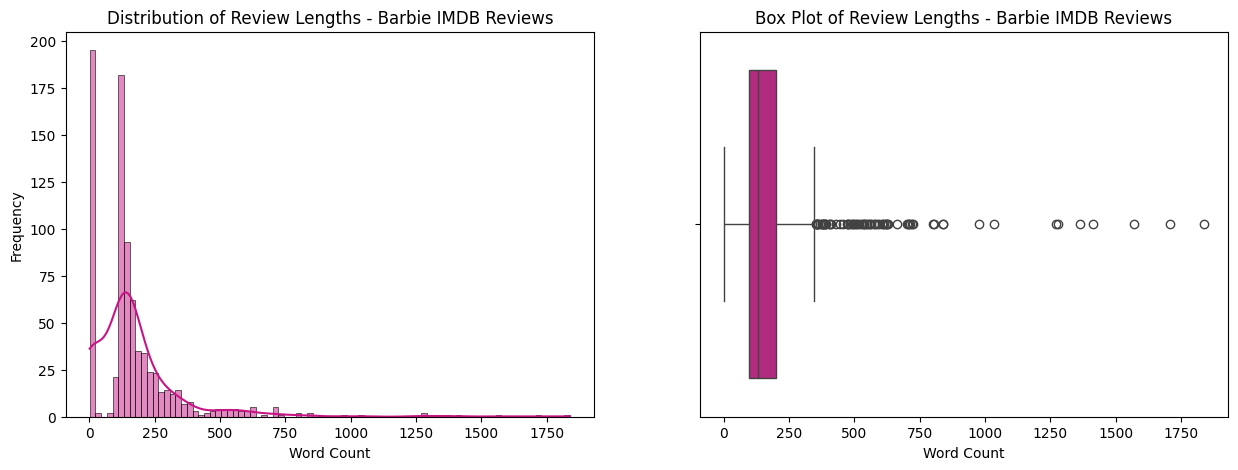

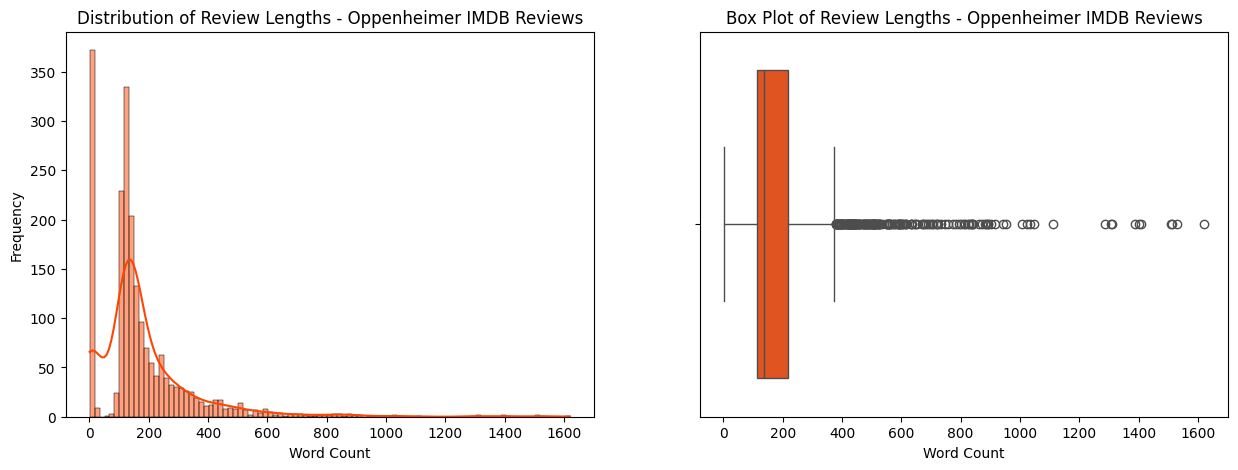

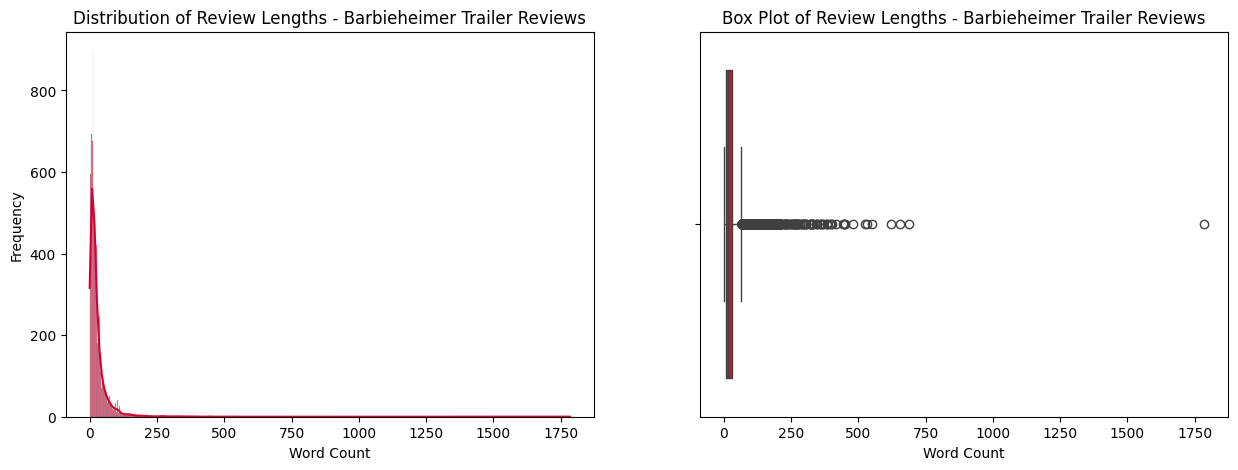

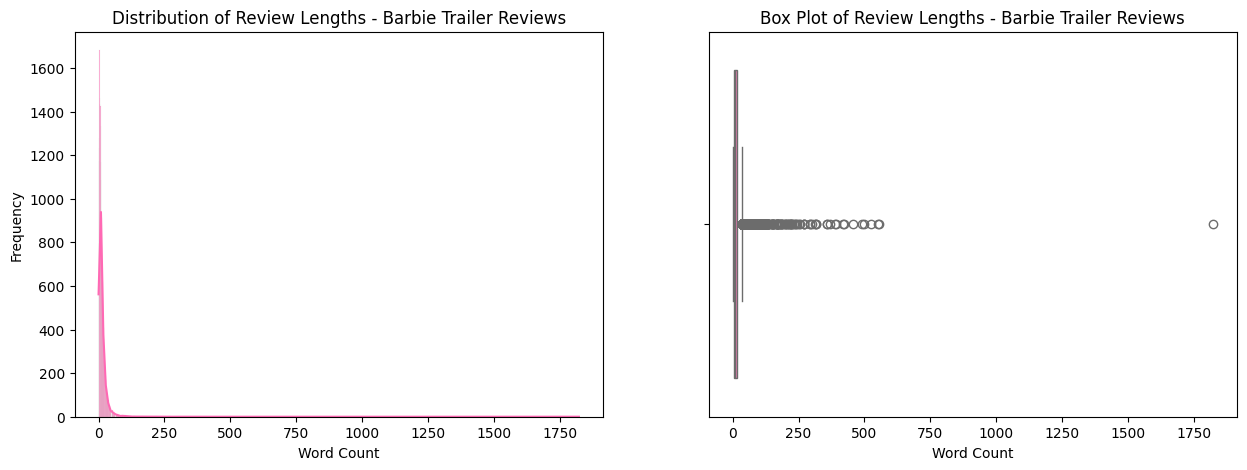

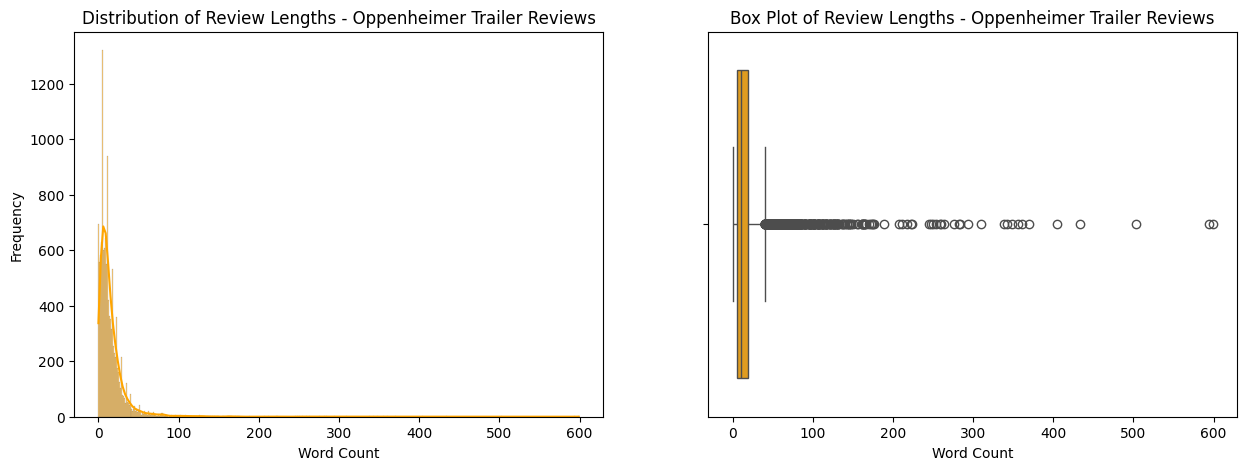

In [ ]:
# Plotting for Barbie
plot_review_length_distribution(barbie_imdb2, 'Barbie IMDB Reviews', '#C71585')  # Using pink color

# Plotting for Oppenheimer
plot_review_length_distribution(oppen_imdb2, 'Oppenheimer IMDB Reviews', '#FF4500')  # Using orange color

# Plotting for Barbieheimer
plot_review_length_distribution(barbieheimer, 'Barbieheimer Trailer Reviews', '#D50032')  # Using red color

# Plotting for Barbie Trailer
plot_review_length_distribution(barbie_trailer, 'Barbie Trailer Reviews', '#FF69B4')  # Using hot pink color

# Plotting for Oppenheimer Trailer
plot_review_length_distribution(oppen_trailer, 'Oppenheimer Trailer Reviews', '#FFA500')  # Using orange color

In [ ]:
# Counting number of Reviews which are outliers
import numpy as np

def count_outliers(df, column_name='Word Count'):
    """Counts the number of outliers in a given column using the IQR method."""
    Q1 = df[column_name].quantile(0.25)
    Q3 = df[column_name].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    outliers = df[(df[column_name] < lower_bound) | (df[column_name] > upper_bound)]
    return len(outliers)

# Count outliers for each dataset
datasets = {
    'Barbie IMDB Reviews': barbie_imdb2,
    'Oppenheimer IMDB Reviews': oppen_imdb2,
    'Barbieheimer Trailer Reviews': barbieheimer,
    'Barbie Trailer Reviews': barbie_trailer,
    'Oppenheimer Trailer Reviews': oppen_trailer
}

for title, df in datasets.items():
    num_outliers = count_outliers(df)
    print(f"Number of outliers in {title}: {num_outliers}")

Number of outliers in Barbie IMDB Reviews: 71
Number of outliers in Oppenheimer IMDB Reviews: 194
Number of outliers in Barbieheimer Trailer Reviews: 806
Number of outliers in Barbie Trailer Reviews: 1411
Number of outliers in Oppenheimer Trailer Reviews: 710


/usr/local/lib/python3.11/dist-packages/ipykernel/ipkernel.py:283: DeprecationWarning: `should_run_async` will not call `transform_cell` automatically in the future. Please pass the result to `transformed_cell` argument and any exception that happen during thetransform in `preprocessing_exc_tuple` in IPython 7.17 and above.
  and should_run_async(code)


In [ ]:
barbie_trailer=barbie_trailer.drop('Sentiment', axis=1) #incorrect sentiments
barbie_trailer.head() #no sentiment

/usr/local/lib/python3.11/dist-packages/ipykernel/ipkernel.py:283: DeprecationWarning: `should_run_async` will not call `transform_cell` automatically in the future. Please pass the result to `transformed_cell` argument and any exception that happen during thetransform in `preprocessing_exc_tuple` in IPython 7.17 and above.
  and should_run_async(code)


,Comment,Word Count
0,Someone know good movie about Klaus Barbie? I ...,19
1,Its Amazin that Barbie gets so much attention ...,24
2,"Meh, saw it, found it quite messy, there were ...",51
3,$1 billion,1
4,This movie should have came out in October to ...,42


In [ ]:
barbie_trailer.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 23956 entries, 0 to 23955
Data columns (total 2 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   Comment     23956 non-null  object
 1   Word Count  23956 non-null  int64 
dtypes: int64(1), object(1)
memory usage: 374.4+ KB


/usr/local/lib/python3.11/dist-packages/ipykernel/ipkernel.py:283: DeprecationWarning: `should_run_async` will not call `transform_cell` automatically in the future. Please pass the result to `transformed_cell` argument and any exception that happen during thetransform in `preprocessing_exc_tuple` in IPython 7.17 and above.
  and should_run_async(code)


In [ ]:
oppen_trailer=oppen_trailer.drop('Sentiment', axis=1) #includes sentiment
oppen_trailer.head() #no sentiment

/usr/local/lib/python3.11/dist-packages/ipykernel/ipkernel.py:283: DeprecationWarning: `should_run_async` will not call `transform_cell` automatically in the future. Please pass the result to `transformed_cell` argument and any exception that happen during thetransform in `preprocessing_exc_tuple` in IPython 7.17 and above.
  and should_run_async(code)


,Comment,Word Count
0,"Epic movie, highly recommended to anyone that ...",11
1,I am grateful to have witnessed this in the Ci...,29
2,Este actor así como toda la película se merece...,20
3,Anyone else still have no idea what the movie ...,11
4,good film,2


In [ ]:
barbieheimer=barbieheimer.drop('Sentiment', axis=1)
barbieheimer.head() #includes sentiment


/usr/local/lib/python3.11/dist-packages/ipykernel/ipkernel.py:283: DeprecationWarning: `should_run_async` will not call `transform_cell` automatically in the future. Please pass the result to `transformed_cell` argument and any exception that happen during thetransform in `preprocessing_exc_tuple` in IPython 7.17 and above.
  and should_run_async(code)


,Comment,Word Count
0,Which one ARE you watching first?<br>---------...,76
1,Oppenheimer. THe Oppenheimer again. And probab...,11
2,"Oppenheimer, I will wait for Barbie on stream.",8
3,None I wish I went for Spider-Man and flash if...,18
4,😂,0


In [ ]:
barbie_imdb.head() #no sentiment included

/usr/local/lib/python3.11/dist-packages/ipykernel/ipkernel.py:283: DeprecationWarning: `should_run_async` will not call `transform_cell` automatically in the future. Please pass the result to `transformed_cell` argument and any exception that happen during thetransform in `preprocessing_exc_tuple` in IPython 7.17 and above.
  and should_run_async(code)


,Review
0,"Beautiful film, but so preachyLoveofLegacy21 J..."
1,Clever and fun beginning turns into another le...
2,It was depressingcoxaneesa24 July 2023Warning:...
3,A Technicolor Dreamheatherhilgers24 July 2023W...
4,reasons FOR seeing it and 1 reason AGAINST.im...


In [ ]:
oppen_imdb.head() #no sentiment included

/usr/local/lib/python3.11/dist-packages/ipykernel/ipkernel.py:283: DeprecationWarning: `should_run_async` will not call `transform_cell` automatically in the future. Please pass the result to `transformed_cell` argument and any exception that happen during thetransform in `preprocessing_exc_tuple` in IPython 7.17 and above.
  and should_run_async(code)


,text
0,You'll have to have your wits about you and yo...
1,One of the most anticipated films of the year ...
2,"""Oppenheimer"" is a biographical thriller film ..."
3,This movie is just... wow! I don't think I hav...
4,I was familiar with the Manhattan project and ...


In [ ]:
print("Barbie Trailer\n",barbie_trailer.describe())
print("Oppenheimer Trailer\n", oppen_trailer.describe())
print("Barbieheimer Youtube\n",barbieheimer.describe())
print("IMDB Barbie\n", barbie_imdb.describe())
print("IMDB Oppenheimer\n", oppen_imdb.describe())

/usr/local/lib/python3.11/dist-packages/ipykernel/ipkernel.py:283: DeprecationWarning: `should_run_async` will not call `transform_cell` automatically in the future. Please pass the result to `transformed_cell` argument and any exception that happen during thetransform in `preprocessing_exc_tuple` in IPython 7.17 and above.
  and should_run_async(code)


Barbie Trailer
          Word Count
count  23956.000000
mean      13.221114
std       22.700936
min        0.000000
25%        4.000000
50%        9.000000
75%       16.000000
max     1823.000000
Oppenheimer Trailer
          Word Count
count  12291.000000
mean      15.760801
std       22.860796
min        0.000000
25%        5.000000
50%       10.000000
75%       19.000000
max      599.000000
Barbieheimer Youtube
         Word Count
count  9374.000000
mean     27.492106
std      44.159547
min       0.000000
25%       8.000000
50%      16.000000
75%      31.000000
max    1785.000000
IMDB Barbie
                                                    Review
count                                                 797
unique                                                797
top     Beautiful film, but so preachyLoveofLegacy21 J...
freq                                                    1
IMDB Oppenheimer
                                                      text
count                          

### Converting Columns to Strings or Text


In [ ]:
barbie1=barbie_trailer['Comment'].to_string(index=False)
#barbie2=barbie_imdb['Review'].to_string(index=False)
barbie2=barbie_imdb2['review_new'].to_string(index=False)
oppen1=oppen_trailer['Comment'].to_string(index=False)
#oppen2=oppen_imdb['text'].to_string(index=False)
oppen2=oppen_imdb2['review_new'].to_string(index=False)
barbieheimer1=barbieheimer['Comment'].to_string(index=False)

/usr/local/lib/python3.11/dist-packages/ipykernel/ipkernel.py:283: DeprecationWarning: `should_run_async` will not call `transform_cell` automatically in the future. Please pass the result to `transformed_cell` argument and any exception that happen during thetransform in `preprocessing_exc_tuple` in IPython 7.17 and above.
  and should_run_async(code)


In [ ]:
# Export text columns as CSV files
datasets = {
    'barbie_imdb_reviews.csv': barbie_imdb2[['review_new']],
    'oppenheimer_imdb_reviews.csv': oppen_imdb2[['review_new']],
    'barbieheimer_trailer_comments.csv': barbieheimer[['Comment']],
    'barbie_trailer_comments.csv': barbie_trailer[['Comment']],
    'oppenheimer_trailer_comments.csv': oppen_trailer[['Comment']]
}

#for filename, df in datasets.items():
    #df.to_csv('/content/drive/My Drive/Natural Language Processing/Exported Files' + filename, index=False)
    #print(f"Exported '{filename}' to Google Drive successfully.")

/usr/local/lib/python3.11/dist-packages/ipykernel/ipkernel.py:283: DeprecationWarning: `should_run_async` will not call `transform_cell` automatically in the future. Please pass the result to `transformed_cell` argument and any exception that happen during thetransform in `preprocessing_exc_tuple` in IPython 7.17 and above.
  and should_run_async(code)


# Preprocessing Text

### Import necessary librairies

In [ ]:
#@title Setup (click the "run" button to the left) {display-mode: "form"}

## Setup ##

# imports

# built-in Python libraries
# -------------------------

# counting and data management
import collections
# operating system utils
import os
# regular expressions
import re
# additional string functions
import string
# system utilities
import sys
# request() will be used to load web content
import urllib.request




# download punctuation related NLTK functions
# (needed for sent_tokenize())
nltk.download('punkt')
# download NLKT part-of-speech tagger
# (needed for pos_tag())
nltk.download('averaged_perceptron_tagger')
# download wordnet
# (needed for lemmatization)
nltk.download('wordnet')
# download stopword lists
# (needed for stopword removal)
nltk.download('stopwords')
# dictionary of English words
nltk.download('words')
nltk.download('omw-1.4')

# numpy: matrix library for Python
import numpy as np

# scipy: scientific operations
# works with numpy objects
import scipy

# matplotlib (and pyplot) for visualizations
import matplotlib
import matplotlib.pyplot as plt

# sklearn for basic machine learning operations
import sklearn
import sklearn.manifold
import sklearn.cluster

# worldcloud tool
!pip install wordcloud
from wordcloud import WordCloud

# for checking object memory usage
!pip install pympler
from pympler import asizeof

!pip install spacy
import spacy


# Ensure all necessary NLTK resources are downloaded
nltk.download('punkt')
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')
nltk.download('punkt_tab')

print()
print("Done with setup!")
print("If you'd like, you can click the (X) button to the left to clear this output.")

/usr/local/lib/python3.11/dist-packages/ipykernel/ipkernel.py:283: DeprecationWarning: `should_run_async` will not call `transform_cell` automatically in the future. Please pass the result to `transformed_cell` argument and any exception that happen during thetransform in `preprocessing_exc_tuple` in IPython 7.17 and above.
  and should_run_async(code)
[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package averaged_perceptron_tagger to
[nltk_data]     /root/nltk_data...
[nltk_data]   Package averaged_perceptron_tagger is already up-to-
[nltk_data]       date!
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package words to /root/nltk_data...
[nltk_data]   Package words is already up-to-date!
[


Done with setup!
If you'd like, you can click the (X) button to the left to clear this output.


[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


In [ ]:
#Preprocessing function

import re
import unicodedata

def text_to_lemma_frequencies(text, remove_stop_words=True):
    # Step 1: Remove URLs (e.g., http://example.com or www.example.com)
    text = re.sub(r'http[s]?://\S+|www\.\S+', '', text)

    # Step 2: Remove all HTML tags (e.g., <br>, <p>, <div>)
    text = re.sub(r'<[^>]+>', '', text)

    # Step 3: Remove common website elements and symbols (e.g., href=, src=)
    text = re.sub(r'\b(?:href|src|alt|id|class|style|title)=["\']?\S+["\']?', '', text)

    # Step 4: Remove all non-alphanumeric characters (except whitespace)
    text = re.sub(r'[^a-zA-Z0-9\s]', ' ', text)

    # Step 5: Expand common slang terms
    slang_mapping = {
        "omg": "oh my god",
        "gon": "going to",
        "gonna": "going to",
        "wanna": "want to",
        "ain't": "is not",
        "u": "you",
        "r": "are",
        "cuz": "because",
        "btw": "by the way",
        "idk": "i do not know"
    }

    for slang, expanded in slang_mapping.items():
        text = re.sub(r'\b' + re.escape(slang) + r'\b', expanded, text)

    # Step 6: Split document into sentences
    sentences = nltk.sent_tokenize(text)

    # Step 7: Create a place to store (word, pos_tag) tuples
    words_and_pos_tags = []

    # Step 8: Tokenize sentences and assign POS tags
    for sentence in sentences:
        words_and_pos_tags += nltk.pos_tag(nltk.word_tokenize(sentence))

    # Step 9: Load the lemmatizer
    lemmatizer = nltk.stem.WordNetLemmatizer()

    # Step 10: Lemmatize words
    lemmas = [lemmatizer.lemmatize(word, lookup_pos(pos)) for word, pos in words_and_pos_tags]

    # Step 11: Convert to lowercase
    lowercase_lemmas = [lemma.lower() for lemma in lemmas]

    # Step 12: Load stopwords
    stop_words = set([])
    if remove_stop_words:
        stop_words = set(nltk.corpus.stopwords.words('english'))

    # Step 13: Add stopwords and custom tokens to removal list
    all_removal_tokens = stop_words | set(string.punctuation) | set(["''", "`", "...", ""])

    # Step 14: Define custom list of meaningless words
    meaningless_words = {"na", "gt", "lt", "im", "amp", "nbsp", "omg", "gon", "quot"}

    # Step 15: Filter out unwanted tokens, single letters, and two-letter words
    content_lemmas = [
        lemma for lemma in lowercase_lemmas
        if lemma not in all_removal_tokens
        and lemma not in meaningless_words
        and not lemma.isdigit()
        and len(lemma) > 2  # Remove single and two-letter words
    ]

    # Step 16: Return frequency distribution object
    return nltk.probability.FreqDist(content_lemmas)

# Lemmatization helper function
def lookup_pos(pos):
    pos_first_char = pos[0].lower()
    if pos_first_char in 'nv':
        return pos_first_char
    else:
        return 'n'

/usr/local/lib/python3.11/dist-packages/ipykernel/ipkernel.py:283: DeprecationWarning: `should_run_async` will not call `transform_cell` automatically in the future. Please pass the result to `transformed_cell` argument and any exception that happen during thetransform in `preprocessing_exc_tuple` in IPython 7.17 and above.
  and should_run_async(code)


**Analysis of the preprocessing steps**

- Removal of Non-Textual Elements : Web scraping often captures non-relevant elements like URLs, HTML tags, and symbols. These elements could be mistakenly considered as tokens, so it’s essential to remove them to ensure clean, meaningful data for analysis.

- Slang Conversion to Full Words : To ensure the text is clear, consistent, and suitable for analysis, slang terms were expanded into full words, eliminating ambiguity and maintaining uniformity throughout the dataset.

- Tokenization : We split sentences into individual words (tokens) to facilitate a more granular level of analysis. This allows us to work with specific terms and their frequencies.

- Lemmatization : Lemmatization reduces words to their root forms, which helps identify similar terms and ensures that variations of a word are treated as one unified concept.

- Lowercasing : Converting all words to lowercase standardizes the text, ensuring that words like "Barbie" and "barbie" are treated as the same token, promoting consistency across the dataset.

- Removal of Stop Words : Stop words do not convey meaningful information for analysis. By removing them, we focus only on significant terms that impact the overall understanding of the text.

- Removal of Punctuation, Meaningless Words, and Digits : These elements typically do not carry semantic value and can introduce noise into the analysis. Therefore, they were eliminated to retain only the most informative parts of the text.

- Part-Of-Speech (POS) Tagging : POS tagging helps identify the grammatical structure of sentences, allowing us to focus on extracting relevant information more accurately.

In [ ]:
# Draw a wordcloud!
# Inputs:
#   word_counts: a dictionary mapping strings to their counts
def draw_wordcloud(freq_dist, colormap):

    #TODO add a few corpus specific checks here to make sure people have done casing, lemmatization, punct removal
    uniq_count = len(freq_dist.keys())
    print("Building a word cloud with",uniq_count,"unique words...")
    wc = WordCloud(colormap=colormap, width=1500,
                   height=1000,background_color="white").generate_from_frequencies(freq_dist)
    plt.imshow(wc, interpolation='bilinear')
    plt.axis("off")


/usr/local/lib/python3.11/dist-packages/ipykernel/ipkernel.py:283: DeprecationWarning: `should_run_async` will not call `transform_cell` automatically in the future. Please pass the result to `transformed_cell` argument and any exception that happen during thetransform in `preprocessing_exc_tuple` in IPython 7.17 and above.
  and should_run_async(code)


In [ ]:
nltk.download('punkt_tab')

/usr/local/lib/python3.11/dist-packages/ipykernel/ipkernel.py:283: DeprecationWarning: `should_run_async` will not call `transform_cell` automatically in the future. Please pass the result to `transformed_cell` argument and any exception that happen during thetransform in `preprocessing_exc_tuple` in IPython 7.17 and above.
  and should_run_async(code)
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


True

In [ ]:
nltk.download('averaged_perceptron_tagger_eng')

/usr/local/lib/python3.11/dist-packages/ipykernel/ipkernel.py:283: DeprecationWarning: `should_run_async` will not call `transform_cell` automatically in the future. Please pass the result to `transformed_cell` argument and any exception that happen during thetransform in `preprocessing_exc_tuple` in IPython 7.17 and above.
  and should_run_async(code)
[nltk_data] Downloading package averaged_perceptron_tagger_eng to
[nltk_data]     /root/nltk_data...
[nltk_data]   Package averaged_perceptron_tagger_eng is already up-to-
[nltk_data]       date!


True

# Sentiment Analysis

##Sentiment Analysis Barbie Pre-Release

In [ ]:
barbie_trailer_SA = pd.read_csv("/content/drive/MyDrive/Natural Language Processing/The Lexical Suite Outputs/barbie_trailer_comments (LS output).csv")
barbie_trailer_SA.head()

/usr/local/lib/python3.11/dist-packages/ipykernel/ipkernel.py:283: DeprecationWarning: `should_run_async` will not call `transform_cell` automatically in the future. Please pass the result to `transformed_cell` argument and any exception that happen during thetransform in `preprocessing_exc_tuple` in IPython 7.17 and above.
  and should_run_async(code)


,original_text,wordcount,valence_min,valence_max,valence_avg,valence_std,extremity_min,extremity_max,extremity_avg,extremity_std,...,count_total_evaluative,count_evaluative_PosMinNeg,ambivalent,pos_dichotomous,certainty_min,certainty_max,certainty_avg,certainty_std,count_unique_certainty,count_total_certainty
0,Someone know good movie about Klaus Barbie? I ...,19,1.44,1.44,1.44,NaN,3.06,3.06,3.060,NaN,...,1,-1.0,0.0,0.0,NaN,NaN,NaN,NaN,0,0
1,Its Amazin that Barbie gets so much attention ...,24,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,0
2,"Meh, saw it, found it quite messy, there were ...",51,2.00,7.84,4.93,2.622,0.72,3.34,2.134,1.19,...,5,-1.0,1.0,NaN,6.83,6.9,6.865,0.049,2,2
3,$1 billion,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,0
4,This movie should have came out in October to ...,42,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,0


In [ ]:
# Replace missing values with 0 for numerical columns
num_cols_bb_pre = ['count_total_evaluative', 'count_total_evaluative_pos',
                   'count_total_evaluative_neg', 'valence_avg',
                   'extremity_avg', 'pos_dichotomous']

# Use barbie_trailer_SA instead of barbie_trailer
barbie_trailer_SA[num_cols_bb_pre] = barbie_trailer_SA[num_cols_bb_pre].fillna(0)

# Use barbie_trailer_SA instead of barbie_trailer to create cleaned dataframe
barbie_trailer_SA_cleaned = barbie_trailer_SA[num_cols_bb_pre]

# Convert columns to float (no need to reassign to barbie_trailer_SA_cleaned)
barbie_trailer_SA_cleaned = barbie_trailer_SA_cleaned.astype(float)

/usr/local/lib/python3.11/dist-packages/ipykernel/ipkernel.py:283: DeprecationWarning: `should_run_async` will not call `transform_cell` automatically in the future. Please pass the result to `transformed_cell` argument and any exception that happen during thetransform in `preprocessing_exc_tuple` in IPython 7.17 and above.
  and should_run_async(code)


In [ ]:
# Calculating the overall sentiment, valence, extremity & ambivalence

# Calculate total number of texts in the cleaned dataframe
total_texts_bb_pre = len(barbie_trailer_SA_cleaned)  # Use the cleaned dataframe
print(f"Total Texts: {total_texts_bb_pre}")

# Valence
average_valence_all_reviews_bb_pre = barbie_trailer_SA_cleaned['valence_avg'].mean()
print(f"Average Valence Score for All Reviews: {average_valence_all_reviews_bb_pre:.2f}")

# Extremity
# Create a new column 'extremity_score' in barbie_trailer_SA_cleaned
barbie_trailer_SA_cleaned['extremity_score'] = barbie_trailer_SA_cleaned['extremity_avg']
avg_extremity_bb_pre = barbie_trailer_SA_cleaned["extremity_avg"].mean()
print(f"Average Extremity across all reviews: {avg_extremity_bb_pre:.2f}")

# Ambivalence
# Create a new column 'is_ambivalent' in barbie_trailer_SA_cleaned
barbie_trailer_SA_cleaned['is_ambivalent'] = barbie_trailer_SA_cleaned['pos_dichotomous']
ambivalent_texts_bb_pre = barbie_trailer_SA_cleaned['pos_dichotomous'].sum()
ambivalence_percentage_bb_pre = (ambivalent_texts_bb_pre / total_texts_bb_pre) * 100
print(f"Ambivalence Percentage: {ambivalence_percentage_bb_pre:.2f}%")

# Overall Sentiment based on valence score
Overall_sentiment_bb_pre = (average_valence_all_reviews_bb_pre / 9) * 100
print(f"Overall Sentiment Percentage: {Overall_sentiment_bb_pre:.2f}%")

Total Texts: 23956
Average Valence Score for All Reviews: 1.66
Average Extremity across all reviews: 0.96
Ambivalence Percentage: 17.08%
Overall Sentiment Percentage: 18.44%


/usr/local/lib/python3.11/dist-packages/ipykernel/ipkernel.py:283: DeprecationWarning: `should_run_async` will not call `transform_cell` automatically in the future. Please pass the result to `transformed_cell` argument and any exception that happen during thetransform in `preprocessing_exc_tuple` in IPython 7.17 and above.
  and should_run_async(code)


##Sentiment Analysis Oppenheimer Pre-Release

In [ ]:
oppen_trailer_SA = pd.read_csv("/content/drive/MyDrive/Natural Language Processing/The Lexical Suite Outputs/oppenheimer_trailer_comments (LS output).csv")
oppen_trailer_SA.head()

/usr/local/lib/python3.11/dist-packages/ipykernel/ipkernel.py:283: DeprecationWarning: `should_run_async` will not call `transform_cell` automatically in the future. Please pass the result to `transformed_cell` argument and any exception that happen during thetransform in `preprocessing_exc_tuple` in IPython 7.17 and above.
  and should_run_async(code)


,original_text,wordcount,valence_min,valence_max,valence_avg,valence_std,extremity_min,extremity_max,extremity_avg,extremity_std,...,count_total_evaluative,count_evaluative_PosMinNeg,ambivalent,pos_dichotomous,certainty_min,certainty_max,certainty_avg,certainty_std,count_unique_certainty,count_total_certainty
0,"Epic movie, highly recommended to anyone that ...",11,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0,NaN,NaN,NaN,6.54,7.31,6.925,0.544,2,2
1,I am grateful to have witnessed this in the Ci...,26,6.96,7.72,7.34,0.537,2.46,3.22,2.84,0.537,...,2,2.0,0.0,1.0,7.60,7.60,7.600,NaN,1,1
2,Este actor así como toda la película se merece...,19,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,0
3,Anyone else still have no idea what the movie ...,11,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0,NaN,NaN,NaN,6.16,6.16,6.160,NaN,1,1
4,good film,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,0


In [ ]:
# Replace missing values with 0 for numerical columns
num_cols_op_pre = ['count_total_evaluative', 'count_total_evaluative_pos',
                   'count_total_evaluative_neg', 'valence_avg',
                   'extremity_avg', 'pos_dichotomous']

oppen_trailer_SA[num_cols_op_pre] = oppen_trailer_SA[num_cols_op_pre].fillna(0)

# Create cleaned dataframe
oppen_trailer_SA_cleaned = oppen_trailer_SA[num_cols_op_pre]

# Convert columns to float
oppen_trailer_SA_cleaned = oppen_trailer_SA_cleaned.astype(float)

/usr/local/lib/python3.11/dist-packages/ipykernel/ipkernel.py:283: DeprecationWarning: `should_run_async` will not call `transform_cell` automatically in the future. Please pass the result to `transformed_cell` argument and any exception that happen during thetransform in `preprocessing_exc_tuple` in IPython 7.17 and above.
  and should_run_async(code)


In [ ]:
# Calculating the overall sentiment, valence, extremity & ambivalence

# Calculate total number of texts in the cleaned dataframe
total_texts_op_pre = len(oppen_trailer_SA_cleaned)
print(f"Total Texts: {total_texts_op_pre}")

# Valence
average_valence_all_reviews_op_pre = oppen_trailer_SA_cleaned['valence_avg'].mean()
print(f"Average Valence Score for All Reviews: {average_valence_all_reviews_op_pre:.2f}")

# Extremity
oppen_trailer_SA_cleaned['extremity_score'] = oppen_trailer_SA_cleaned['extremity_avg']
avg_extremity_op_pre = oppen_trailer_SA_cleaned["extremity_avg"].mean()
print(f"Average Extremity across all reviews: {avg_extremity_op_pre:.2f}")

# Ambivalence
oppen_trailer_SA_cleaned['is_ambivalent'] = oppen_trailer_SA_cleaned['pos_dichotomous']
ambivalent_texts_op_pre = oppen_trailer_SA_cleaned['pos_dichotomous'].sum()
ambivalence_percentage_op_pre = (ambivalent_texts_op_pre / total_texts_op_pre) * 100
print(f"Ambivalence Percentage: {ambivalence_percentage_op_pre:.2f}%")

# Overall Sentiment based on valence score
Overall_sentiment_op_pre = (average_valence_all_reviews_op_pre / 9) * 100
print(f"Overall Sentiment Percentage: {Overall_sentiment_op_pre:.2f}%")

Total Texts: 12291
Average Valence Score for All Reviews: 1.87
Average Extremity across all reviews: 0.91
Ambivalence Percentage: 20.94%
Overall Sentiment Percentage: 20.72%


/usr/local/lib/python3.11/dist-packages/ipykernel/ipkernel.py:283: DeprecationWarning: `should_run_async` will not call `transform_cell` automatically in the future. Please pass the result to `transformed_cell` argument and any exception that happen during thetransform in `preprocessing_exc_tuple` in IPython 7.17 and above.
  and should_run_async(code)


##Sentiment Analysis Barbenheimer Pre-Release

In [ ]:
barbieheimer_SA = pd.read_csv("/content/drive/MyDrive/Natural Language Processing/The Lexical Suite Outputs/barbieheimer_trailer_comments (LS output).csv")
barbieheimer_SA.head()

/usr/local/lib/python3.11/dist-packages/ipykernel/ipkernel.py:283: DeprecationWarning: `should_run_async` will not call `transform_cell` automatically in the future. Please pass the result to `transformed_cell` argument and any exception that happen during thetransform in `preprocessing_exc_tuple` in IPython 7.17 and above.
  and should_run_async(code)


,original_text,wordcount,valence_min,valence_max,valence_avg,valence_std,extremity_min,extremity_max,extremity_avg,extremity_std,...,count_total_evaluative,count_evaluative_PosMinNeg,ambivalent,pos_dichotomous,certainty_min,certainty_max,certainty_avg,certainty_std,count_unique_certainty,count_total_certainty
0,Which one ARE you watching first?<br>---------...,39,1.07,8.07,5.577,3.91,3.09,3.57,3.363,0.247,...,3,1.0,1.0,NaN,3.68,6.09,4.885,1.704,2,2
1,Oppenheimer. THe Oppenheimer again. And probab...,11,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0,NaN,NaN,NaN,4.03,4.03,4.030,NaN,1,1
2,"Oppenheimer, I will wait for Barbie on stream.",8,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,0
3,None I wish I went for Spider-Man and flash if...,17,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0,NaN,NaN,NaN,7.41,7.41,7.410,NaN,1,1
4,😂,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,0


In [ ]:
# Replace missing values with 0 for numerical columns
num_cols_bo_pre = ['count_total_evaluative', 'count_total_evaluative_pos',
                   'count_total_evaluative_neg', 'valence_avg',
                   'extremity_avg', 'pos_dichotomous']

barbieheimer_SA[num_cols_bo_pre] = barbieheimer_SA[num_cols_bo_pre].fillna(0)

# Create cleaned dataframe
barbieheimer_SA_cleaned = barbieheimer_SA[num_cols_bo_pre]

# Convert columns to float
barbieheimer_SA_cleaned = barbieheimer_SA_cleaned.astype(float)

/usr/local/lib/python3.11/dist-packages/ipykernel/ipkernel.py:283: DeprecationWarning: `should_run_async` will not call `transform_cell` automatically in the future. Please pass the result to `transformed_cell` argument and any exception that happen during thetransform in `preprocessing_exc_tuple` in IPython 7.17 and above.
  and should_run_async(code)


In [ ]:
# Calculating the overall sentiment, valence, extremity & ambivalence

# Calculate total number of texts in the cleaned dataframe
total_texts_bo_pre = len(barbieheimer_SA_cleaned)
print(f"Total Texts: {total_texts_bo_pre}")

# Valence
average_valence_all_reviews_bo_pre = barbieheimer_SA_cleaned['valence_avg'].mean()
print(f"Average Valence Score for All Reviews: {average_valence_all_reviews_bo_pre:.2f}")

# Extremity
barbieheimer_SA_cleaned['extremity_score'] = barbieheimer_SA_cleaned['extremity_avg']
avg_extremity_bo_pre = barbieheimer_SA_cleaned["extremity_avg"].mean()
print(f"Average Extremity across all reviews: {avg_extremity_bo_pre:.2f}")

# Ambivalence
barbieheimer_SA_cleaned['is_ambivalent'] = barbieheimer_SA_cleaned['pos_dichotomous']
ambivalent_texts_bo_pre = barbieheimer_SA_cleaned['pos_dichotomous'].sum()
ambivalence_percentage_bo_pre = (ambivalent_texts_bo_pre / total_texts_bo_pre) * 100
print(f"Ambivalence Percentage: {ambivalence_percentage_bo_pre:.2f}%")

# Overall Sentiment based on valence score
Overall_sentiment_bo_pre = (average_valence_all_reviews_bo_pre / 9) * 100
print(f"Overall Sentiment Percentage: {Overall_sentiment_bo_pre:.2f}%")

/usr/local/lib/python3.11/dist-packages/ipykernel/ipkernel.py:283: DeprecationWarning: `should_run_async` will not call `transform_cell` automatically in the future. Please pass the result to `transformed_cell` argument and any exception that happen during thetransform in `preprocessing_exc_tuple` in IPython 7.17 and above.
  and should_run_async(code)


Total Texts: 9374
Average Valence Score for All Reviews: 2.22
Average Extremity across all reviews: 1.24
Ambivalence Percentage: 20.45%
Overall Sentiment Percentage: 24.64%


##Sentiment Analysis Barbie Post-Realease

In [ ]:
barbie_imdb_SA = pd.read_csv("/content/drive/MyDrive/Natural Language Processing/The Lexical Suite Outputs/barbie_imdb_clean (LS output).csv")
barbie_imdb_SA.head()

/usr/local/lib/python3.11/dist-packages/ipykernel/ipkernel.py:283: DeprecationWarning: `should_run_async` will not call `transform_cell` automatically in the future. Please pass the result to `transformed_cell` argument and any exception that happen during thetransform in `preprocessing_exc_tuple` in IPython 7.17 and above.
  and should_run_async(code)


,original_text,wordcount,valence_min,valence_max,valence_avg,valence_std,extremity_min,extremity_max,extremity_avg,extremity_std,...,count_total_evaluative,count_evaluative_PosMinNeg,ambivalent,pos_dichotomous,certainty_min,certainty_max,certainty_avg,certainty_std,count_unique_certainty,count_total_certainty
0,"Beautiful film, but so preachyLoveofLegacyMarg...",148,1.12,8.45,5.687,2.956,0.70,3.95,2.809,1.239,...,10,4.0,1.0,NaN,1.92,7.33,5.688,1.685,8,9
1,Clever and fun beginning turns into another le...,114,1.44,7.84,5.543,3.010,2.39,3.34,2.917,0.399,...,6,2.0,1.0,NaN,5.23,7.64,6.303,1.226,3,3
2,It was depressingcoxaneesa,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0,NaN,NaN,NaN,7.33,7.33,7.330,NaN,1,1
3,"A Technicolor DreamheatherhilgersWow, this mov...",219,1.60,8.27,6.272,2.724,0.18,3.77,2.798,1.337,...,6,2.0,1.0,NaN,5.73,8.15,6.916,0.808,9,9
4,reasons FOR seeing it and 1 reason AGAINST.imseeg,8,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0,NaN,NaN,NaN,7.04,7.04,7.040,NaN,1,1


In [ ]:
# Replace missing values with 0 for numerical columns
num_cols_bb_post = ['count_total_evaluative', 'count_total_evaluative_pos',
                   'count_total_evaluative_neg', 'valence_avg',
                   'extremity_avg', 'pos_dichotomous']

barbie_imdb_SA[num_cols_bb_post] = barbie_imdb_SA[num_cols_bb_post].fillna(0)

# Create cleaned dataframe
barbie_imdb_SA_cleaned = barbie_imdb_SA[num_cols_bb_post]

# Convert columns to float
barbie_imdb_SA_cleaned = barbie_imdb_SA_cleaned.astype(float)

/usr/local/lib/python3.11/dist-packages/ipykernel/ipkernel.py:283: DeprecationWarning: `should_run_async` will not call `transform_cell` automatically in the future. Please pass the result to `transformed_cell` argument and any exception that happen during thetransform in `preprocessing_exc_tuple` in IPython 7.17 and above.
  and should_run_async(code)


In [ ]:
# Calculating the overall sentiment, valence, extremity & ambivalence

# Calculate total number of texts in the cleaned dataframe
total_texts_bb_post = len(barbie_imdb_SA_cleaned)
print(f"Total Texts: {total_texts_bb_post}")

# Valence
average_valence_all_reviews_bb_post = barbie_imdb_SA_cleaned['valence_avg'].mean()
print(f"Average Valence Score for All Reviews: {average_valence_all_reviews_bb_post:.2f}")

# Extremity
barbie_imdb_SA_cleaned['extremity_score'] = barbie_imdb_SA_cleaned['extremity_avg']
avg_extremity_bb_post = barbie_imdb_SA_cleaned["extremity_avg"].mean()
print(f"Average Extremity across all reviews: {avg_extremity_bb_post:.2f}")

# Ambivalence
barbie_imdb_SA_cleaned['is_ambivalent'] = barbie_imdb_SA_cleaned['pos_dichotomous']
ambivalent_texts_bb_post = barbie_imdb_SA_cleaned['pos_dichotomous'].sum()
ambivalence_percentage_bb_post = (ambivalent_texts_bb_post / total_texts_bb_post) * 100
print(f"Ambivalence Percentage: {ambivalence_percentage_bb_post:.2f}%")

# Overall Sentiment based on valence score
Overall_sentiment_bb_post = (average_valence_all_reviews_bb_post / 9) * 100
print(f"Overall Sentiment Percentage: {Overall_sentiment_bb_post:.2f}%")

Total Texts: 797
Average Valence Score for All Reviews: 5.27
Average Extremity across all reviews: 2.46
Ambivalence Percentage: 25.47%
Overall Sentiment Percentage: 58.53%


/usr/local/lib/python3.11/dist-packages/ipykernel/ipkernel.py:283: DeprecationWarning: `should_run_async` will not call `transform_cell` automatically in the future. Please pass the result to `transformed_cell` argument and any exception that happen during thetransform in `preprocessing_exc_tuple` in IPython 7.17 and above.
  and should_run_async(code)


##Sentiment Analysis Oppenheimer Post-Release

In [ ]:
oppen_imdb_SA = pd.read_csv("/content/drive/MyDrive/Natural Language Processing/The Lexical Suite Outputs/oppen_imdb_clean (LS output).csv")
oppen_imdb_SA.head()

/usr/local/lib/python3.11/dist-packages/ipykernel/ipkernel.py:283: DeprecationWarning: `should_run_async` will not call `transform_cell` automatically in the future. Please pass the result to `transformed_cell` argument and any exception that happen during thetransform in `preprocessing_exc_tuple` in IPython 7.17 and above.
  and should_run_async(code)


,original_text,wordcount,valence_min,valence_max,valence_avg,valence_std,extremity_min,extremity_max,extremity_avg,extremity_std,...,count_total_evaluative,count_evaluative_PosMinNeg,ambivalent,pos_dichotomous,certainty_min,certainty_max,certainty_avg,certainty_std,count_unique_certainty,count_total_certainty
0,"A challenging watch to be sure, but a worthwhi...",364,1.24,8.45,6.554,1.930,0.34,3.95,2.536,1.191,...,25,21.0,1.0,NaN,3.79,8.00,6.170,1.185,19,22
1,A brilliantly layered examination of a man thr...,1581,0.70,8.45,5.929,2.339,0.18,3.95,2.507,1.075,...,60,24.0,1.0,NaN,2.00,8.28,5.929,1.417,53,59
2,Nolan delivers a powerfull biopic that shows t...,198,1.24,8.45,6.412,2.548,0.70,3.95,2.959,0.939,...,11,7.0,1.0,NaN,2.85,7.33,5.223,1.527,9,9
3,A Masterpiecemohameddawoud-26019I may consider...,113,1.26,8.45,6.275,2.887,0.22,3.95,2.928,1.351,...,6,2.0,1.0,NaN,3.45,8.00,6.040,1.560,8,8
4,And the Oscar goes to...mark-217-307033I'm sti...,142,1.32,8.45,6.580,2.635,2.50,3.95,3.140,0.552,...,6,4.0,1.0,NaN,3.68,4.64,4.000,0.554,2,3


In [ ]:
# Replace missing values with 0 for numerical columns
num_cols_op_post = ['count_total_evaluative', 'count_total_evaluative_pos',
                   'count_total_evaluative_neg', 'valence_avg',
                   'extremity_avg', 'pos_dichotomous']

oppen_imdb_SA[num_cols_op_post] = oppen_imdb_SA[num_cols_op_post].fillna(0)

# Create cleaned dataframe
oppen_imdb_SA_cleaned = oppen_imdb_SA[num_cols_op_post]

# Convert columns to float
oppen_imdb_SA_cleaned = oppen_imdb_SA_cleaned.astype(float)

/usr/local/lib/python3.11/dist-packages/ipykernel/ipkernel.py:283: DeprecationWarning: `should_run_async` will not call `transform_cell` automatically in the future. Please pass the result to `transformed_cell` argument and any exception that happen during thetransform in `preprocessing_exc_tuple` in IPython 7.17 and above.
  and should_run_async(code)


In [ ]:
# Calculating the overall sentiment, valence, extremity & ambivalence

# Calculate total number of texts in the cleaned dataframe
total_texts_op_post = len(oppen_imdb_SA_cleaned)
print(f"Total Texts: {total_texts_op_post}")

# Valence
average_valence_all_reviews_op_post = oppen_imdb_SA_cleaned['valence_avg'].mean()
print(f"Average Valence Score for All Reviews: {average_valence_all_reviews_op_post:.2f}")

# Extremity
oppen_imdb_SA_cleaned['extremity_score'] = oppen_imdb_SA_cleaned['extremity_avg']
avg_extremity_op_post = oppen_imdb_SA_cleaned["extremity_avg"].mean()
print(f"Average Extremity across all reviews: {avg_extremity_op_post:.2f}")

# Ambivalence
oppen_imdb_SA_cleaned['is_ambivalent'] = oppen_imdb_SA_cleaned['pos_dichotomous']
ambivalent_texts_op_post = oppen_imdb_SA_cleaned['pos_dichotomous'].sum()
ambivalence_percentage_op_post = (ambivalent_texts_op_post / total_texts_op_post) * 100
print(f"Ambivalence Percentage: {ambivalence_percentage_op_post:.2f}%")

# Overall Sentiment based on valence score
Overall_sentiment_op_post = (average_valence_all_reviews_op_post / 9) * 100
print(f"Overall Sentiment Percentage: {Overall_sentiment_op_post:.2f}%")

Total Texts: 2036
Average Valence Score for All Reviews: 5.37
Average Extremity across all reviews: 2.43
Ambivalence Percentage: 25.10%
Overall Sentiment Percentage: 59.66%


/usr/local/lib/python3.11/dist-packages/ipykernel/ipkernel.py:283: DeprecationWarning: `should_run_async` will not call `transform_cell` automatically in the future. Please pass the result to `transformed_cell` argument and any exception that happen during thetransform in `preprocessing_exc_tuple` in IPython 7.17 and above.
  and should_run_async(code)


# Word Clouds and Frequency Distribution


## Barbie reviews preprocessing

In [ ]:
# Concatenating barbie 1 and barbie 2
barbie = barbie1 + '\n' + barbie2

/usr/local/lib/python3.11/dist-packages/ipykernel/ipkernel.py:283: DeprecationWarning: `should_run_async` will not call `transform_cell` automatically in the future. Please pass the result to `transformed_cell` argument and any exception that happen during thetransform in `preprocessing_exc_tuple` in IPython 7.17 and above.
  and should_run_async(code)


/usr/local/lib/python3.11/dist-packages/ipykernel/ipkernel.py:283: DeprecationWarning: `should_run_async` will not call `transform_cell` automatically in the future. Please pass the result to `transformed_cell` argument and any exception that happen during thetransform in `preprocessing_exc_tuple` in IPython 7.17 and above.
  and should_run_async(code)


Building a word cloud with 7277 unique words...


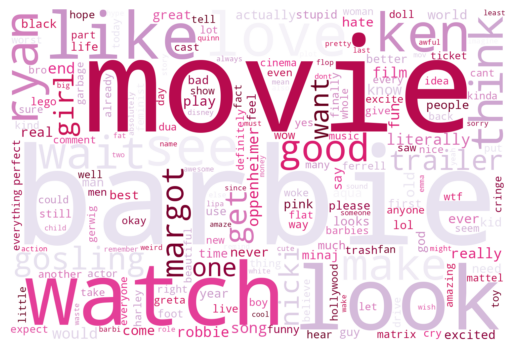

In [ ]:
# Get the word frequency distribution
freq_dist = text_to_lemma_frequencies(barbie)

# Use default colormap
colormap = "PuRd"
# Bonus: try out some other matplotlib colormaps
#colormap = "spring" # see more here: https://matplotlib.org/3.1.0/tutorials/colors/colormaps.html

# Call the function to draw the word cloud
draw_wordcloud(freq_dist, colormap)

/usr/local/lib/python3.11/dist-packages/ipykernel/ipkernel.py:283: DeprecationWarning: `should_run_async` will not call `transform_cell` automatically in the future. Please pass the result to `transformed_cell` argument and any exception that happen during thetransform in `preprocessing_exc_tuple` in IPython 7.17 and above.
  and should_run_async(code)


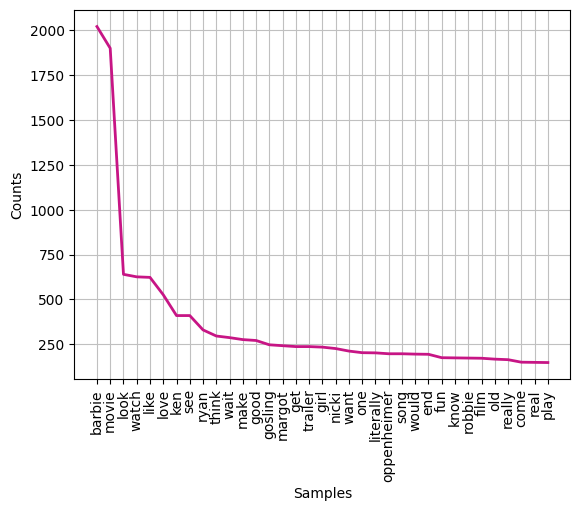

In [ ]:
# Barbie Frequency distribution
freq_dist = text_to_lemma_frequencies(barbie, remove_stop_words=True)
top_n_words = 35
freq_dist.plot(top_n_words, cumulative=False, color='#C71585', linewidth=2)
plt.show()

**Analysis & key takeaways**

- "Barbie" Dominance: The high frequency of "Barbie" indicates that the film was the primary subject of these discussions.

- Viewing Experience: Words like "movie" and "watch" emphasize that the reviews focus on the experience of watching the film.

- Positive Reception: The presence of words like "love," "like," "good," and "fun" suggests a generally positive reception for the film.

- Supporting Cast: "Ken", "Ryan" and "Margot Robbie" being dominant suggests that the supporting characters and performances were a significant aspect of the film's reception.

- Oppenheimer's Presence: While "Oppenheimer" appears, its lower frequency compared to "Barbie" indicates that it wasn't as dominant a topic in these reviews.

## Oppenheimer reviews preprocessing

In [ ]:
# Concatenate Oppen1 and Oppen2
oppen = oppen1 + '\n' + oppen2


/usr/local/lib/python3.11/dist-packages/ipykernel/ipkernel.py:283: DeprecationWarning: `should_run_async` will not call `transform_cell` automatically in the future. Please pass the result to `transformed_cell` argument and any exception that happen during thetransform in `preprocessing_exc_tuple` in IPython 7.17 and above.
  and should_run_async(code)


/usr/local/lib/python3.11/dist-packages/ipykernel/ipkernel.py:283: DeprecationWarning: `should_run_async` will not call `transform_cell` automatically in the future. Please pass the result to `transformed_cell` argument and any exception that happen during thetransform in `preprocessing_exc_tuple` in IPython 7.17 and above.
  and should_run_async(code)


Building a word cloud with 6893 unique words...


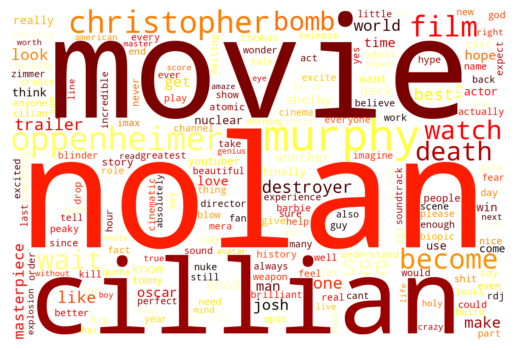

In [ ]:
# Get the word frequency distribution
freq_dist2 = text_to_lemma_frequencies(oppen)

# Use default colormap
colormap = "hot"
# Bonus: try out some other matplotlib colormaps
#colormap = "spring" # see more here: https://matplotlib.org/3.1.0/tutorials/colors/colormaps.html

# Call the function to draw the word cloud
draw_wordcloud(freq_dist2, colormap)

/usr/local/lib/python3.11/dist-packages/ipykernel/ipkernel.py:283: DeprecationWarning: `should_run_async` will not call `transform_cell` automatically in the future. Please pass the result to `transformed_cell` argument and any exception that happen during thetransform in `preprocessing_exc_tuple` in IPython 7.17 and above.
  and should_run_async(code)


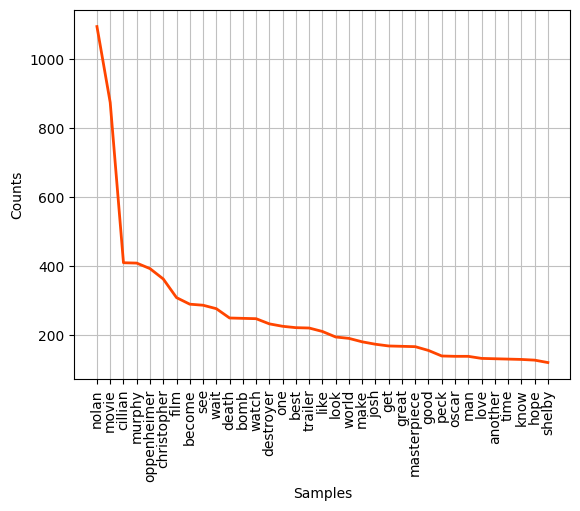

In [ ]:
# oppenheimer Frequency distribution
freq_dist2 = text_to_lemma_frequencies(oppen, remove_stop_words=True)
top_n_words = 35
freq_dist2.plot(top_n_words, cumulative=False,color='#FF4500', linewidth=2)
plt.show()

**Analysis & key takeaways**

- Oppenheimer and Nolan: The dominance of "Oppenheimer" and "Christopher Nolan" is unsurprising, as they are the central figures of the film.

- Cillian Murphy: The frequent mention of "Cillian Murphy" suggests that his performance is a significant aspect of the film's reception.

- Cinematic Focus: The presence of words like "movie," "watch," "film," and "trailer" indicates that the reviews are mostly focused on the cinematic experience and the film's presentation.

- Themes of Destruction: Words like "bomb," "death," "destroy," and "world" align with the film's exploration of the profound and destructive impact of the atomic bomb.

- Mixed Sentiment: While words like "best," "masterpiece," and "love" suggest some positive sentiment, they are not as frequent indicating a potentially mixed reception for "Oppenheimer" .

## Barbieheimer reviews preprocessing

/usr/local/lib/python3.11/dist-packages/ipykernel/ipkernel.py:283: DeprecationWarning: `should_run_async` will not call `transform_cell` automatically in the future. Please pass the result to `transformed_cell` argument and any exception that happen during thetransform in `preprocessing_exc_tuple` in IPython 7.17 and above.
  and should_run_async(code)


Building a word cloud with 4362 unique words...


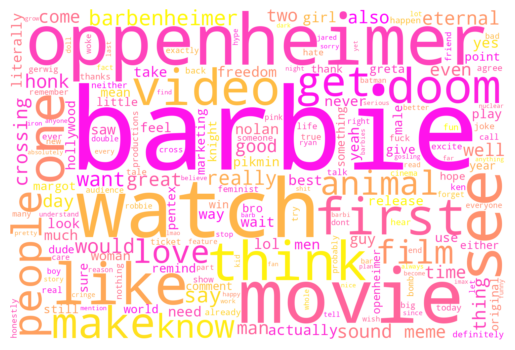

In [ ]:
# Get the word frequency distribution
freq_dist3 = text_to_lemma_frequencies(barbieheimer1)

# Use default colormap
colormap = "spring"
# Bonus: try out some other matplotlib colormaps
#colormap = "spring" # see more here: https://matplotlib.org/3.1.0/tutorials/colors/colormaps.html

# Call the function to draw the word cloud
draw_wordcloud(freq_dist3, colormap)


/usr/local/lib/python3.11/dist-packages/ipykernel/ipkernel.py:283: DeprecationWarning: `should_run_async` will not call `transform_cell` automatically in the future. Please pass the result to `transformed_cell` argument and any exception that happen during thetransform in `preprocessing_exc_tuple` in IPython 7.17 and above.
  and should_run_async(code)


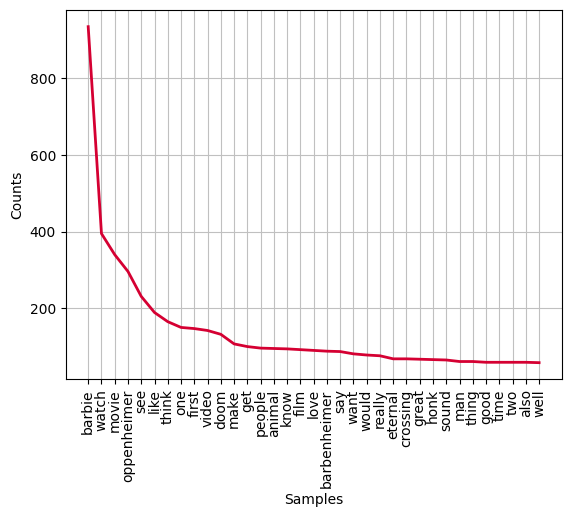

In [ ]:
# Barbieheimer Frequency distribution
freq_dist3 = text_to_lemma_frequencies(barbieheimer1, remove_stop_words=True)
top_n_words = 35
freq_dist3.plot(top_n_words, cumulative=False,color='#D50032', linewidth=2)
plt.show()

**Analysis**

- "Barbie" and "Oppenheimer": Central themes, highlighting the two films.

- Viewership Indicators: Words like watch, movie, see, and go suggest a focus on desire to view the films.

- Positive Sentiment: Words such as like, love, great, and good reflect viewers' favorable reactions.

- Emotional & Personal Reflection: Words like make, get, think and know indicate that reviews often highlight viewers' emotional responses and personal takeaways.

- Comparisons: Terms like "First," "Time," and "Two" point to comparisons, emphasizing the unique qualities of each film.

- Oppenheimer’s Serious Themes: The word "doom" refers to Oppenheimer's themes related to the atomic bomb and its global implications.

- Barbie’s Emotional Impact: The word "love" is a key theme for Barbie, evoking strong, positive emotions.

**Key takeaways**

- Strong Viewer Engagement : High level of engagement is reflected in the dominant words, showcasing a strong connection with both films. Focus on desire to watch, view, and engage with the films.

- Barbie - Eliciting Strong Positive Emotions : Barbie resonates strongly on an emotional level, generating positivity and excitement.

- Virality and Word-of-Mouth : Positive reactions from viewers encourage recommendations, driving others to watch.

- Oppenheimer Serious Themes and Viewer Impact : Oppenheimer's heavy themes spark deep reflection on humanity’s future and the implications of technology.

# Topic Modelling

In [ ]:

barbie_trailer = pd.read_csv("/content/drive/My Drive/Natural Language Processing/Trailer Reviews/barbie.csv", nrows=500) #reviews from youtube trailer
oppen_trailer = pd.read_csv("/content/drive/My Drive/Natural Language Processing/Trailer Reviews/oppenheimer.csv", nrows=500) #reviews from youtube trailer
barbieheimer = pd.read_csv("/content/drive/My Drive/Natural Language Processing/Trailer Reviews/barbieheimer.csv" , nrows=500) #reviews from youtube
barbie_imdb = pd.read_csv("/content/drive/My Drive/Natural Language Processing/IMDB Reviews/barbie_imdb_clean.csv", nrows=500) #reviews from IMDB
oppen_imdb = pd.read_csv("/content/drive/My Drive/Natural Language Processing/IMDB Reviews/oppen_imdb_clean.csv", nrows=500) #reviews from IMDB


/usr/local/lib/python3.11/dist-packages/ipykernel/ipkernel.py:283: DeprecationWarning: `should_run_async` will not call `transform_cell` automatically in the future. Please pass the result to `transformed_cell` argument and any exception that happen during thetransform in `preprocessing_exc_tuple` in IPython 7.17 and above.
  and should_run_async(code)


In [ ]:
# Load English NLP model
nlp = spacy.load("en_core_web_sm")
spell = Speller(lang='en')

stopword_list = set(stopwords.words("english"))

def clean_text(text):
    # Handle missing values & convert to string
    if pd.isnull(text) or not isinstance(text, str):
        return ""

    text = text.lower()  # Convert to lowercase
    text = re.sub(r"http\S+|www\S+|https\S+", "", text)  # Remove URLs
    text = re.sub(r'\d+', '', text)  # Remove numbers
    text = re.sub(r'\s+', ' ', text).strip()  # Remove extra spaces
    # Remove all HTML tags (e.g., <br>, <p>, <div>)
    text = re.sub(r'<[^>]+>', '', text)

    # Remove common website elements and symbols (e.g., href=, src=)
    text = re.sub(r'\b(?:href|src|alt|id|class|style|title)=["\']?\S+["\']?', '', text)
    # Remove all non-alphanumeric characters (except whitespace)
    text = re.sub(r'[^a-zA-Z0-9\s]', ' ', text)
    # Step 5: Expand common slang terms
    slang_mapping = {
        "omg": "oh my god",
        "gon": "going to",
        "gonna": "going to",
        "wanna": "want to",
        "ain't": "is not",
        "u": "you",
        "r": "are",
        "cuz": "because",
        "btw": "by the way",
        "idk": "i do not know"
    }

    for slang, expanded in slang_mapping.items():
        text = re.sub(r'\b' + re.escape(slang) + r'\b', expanded, text)
 # Define custom list of meaningless words
    meaningless_words = {"na", "gt", "lt", "im", "amp", "nbsp", "omg", "gon", "quot"}
    stopword_list.update(meaningless_words)
    text = contractions.fix(text)  # Expand contractions
    text = unicodedata.normalize('NFKD', text).encode('ascii', 'ignore').decode()  # Remove accents


    # Tokenization & stopword removal
    tokens = word_tokenize(text)
    tokens = [word for word in tokens if word not in stopword_list and word not in string.punctuation]

    # Lemmatization
    lemmatized_tokens = [nlp(word)[0].lemma_ for word in tokens]

    return " ".join(lemmatized_tokens)

/usr/local/lib/python3.11/dist-packages/ipykernel/ipkernel.py:283: DeprecationWarning: `should_run_async` will not call `transform_cell` automatically in the future. Please pass the result to `transformed_cell` argument and any exception that happen during thetransform in `preprocessing_exc_tuple` in IPython 7.17 and above.
  and should_run_async(code)


In [ ]:
barbie_trailer["clean_text"] = barbie_trailer.iloc[:, 0].apply(clean_text)
oppen_trailer["clean_text"] = oppen_trailer.iloc[:, 0].apply(clean_text)
barbie_imdb["clean_text"] = barbie_imdb.iloc[:, 0].apply(clean_text)
oppen_imdb["clean_text"] = oppen_imdb.iloc[:, 0].apply(clean_text)

/usr/local/lib/python3.11/dist-packages/ipykernel/ipkernel.py:283: DeprecationWarning: `should_run_async` will not call `transform_cell` automatically in the future. Please pass the result to `transformed_cell` argument and any exception that happen during thetransform in `preprocessing_exc_tuple` in IPython 7.17 and above.
  and should_run_async(code)


In [ ]:
def prepare_lda_data(texts):
    tokenized_texts = [word_tokenize(text) for text in texts.dropna()]
    dictionary = corpora.Dictionary(tokenized_texts)
    corpus = [dictionary.doc2bow(text) for text in tokenized_texts]
    return dictionary, corpus, tokenized_texts

/usr/local/lib/python3.11/dist-packages/ipykernel/ipkernel.py:283: DeprecationWarning: `should_run_async` will not call `transform_cell` automatically in the future. Please pass the result to `transformed_cell` argument and any exception that happen during thetransform in `preprocessing_exc_tuple` in IPython 7.17 and above.
  and should_run_async(code)


In [ ]:
barbie_trailer_dict, barbie_trailer_corpus, barbie_trailer_tokens = prepare_lda_data(barbie_trailer["clean_text"])
oppen_trailer_dict, oppen_trailer_corpus, oppen_trailer_tokens = prepare_lda_data(oppen_trailer["clean_text"])
barbie_imdb_dict, barbie_imdb_corpus, barbie_imdb_tokens = prepare_lda_data(barbie_imdb["clean_text"])
oppen_imdb_dict, oppen_imdb_corpus, oppen_imdb_tokens = prepare_lda_data(oppen_imdb["clean_text"])

/usr/local/lib/python3.11/dist-packages/ipykernel/ipkernel.py:283: DeprecationWarning: `should_run_async` will not call `transform_cell` automatically in the future. Please pass the result to `transformed_cell` argument and any exception that happen during thetransform in `preprocessing_exc_tuple` in IPython 7.17 and above.
  and should_run_async(code)


In [ ]:
def perform_lda(dictionary, corpus, num_topics=3):
    lda_model = models.LdaModel(corpus, num_topics=num_topics, id2word=dictionary, passes=10)
    return lda_model

barbie_trailer_lda = perform_lda(barbie_trailer_dict, barbie_trailer_corpus)
oppen_trailer_lda = perform_lda(oppen_trailer_dict, oppen_trailer_corpus)
barbie_imdb_lda = perform_lda(barbie_imdb_dict, barbie_imdb_corpus)
oppen_imdb_lda = perform_lda(oppen_imdb_dict, oppen_imdb_corpus)

/usr/local/lib/python3.11/dist-packages/ipykernel/ipkernel.py:283: DeprecationWarning: `should_run_async` will not call `transform_cell` automatically in the future. Please pass the result to `transformed_cell` argument and any exception that happen during thetransform in `preprocessing_exc_tuple` in IPython 7.17 and above.
  and should_run_async(code)


In [ ]:
def print_topics(lda_model, title):
    print(f"\n🔹 Topics for {title}:\n")
    for topic in lda_model.print_topics():
        print(topic)

print_topics(barbie_trailer_lda, "Barbie (Pre-Release YouTube)")
print_topics(oppen_trailer_lda, "Oppenheimer (Pre-Release YouTube)")
print_topics(barbie_imdb_lda, "Barbie (Post-Release IMDB)")
print_topics(oppen_imdb_lda, "Oppenheimer (Post-Release IMDB)")


🔹 Topics for Barbie (Pre-Release YouTube):

(0, '0.064*"movie" + 0.028*"watch" + 0.011*"see" + 0.010*"barbie" + 0.010*"love" + 0.008*"man" + 0.008*"trailer" + 0.008*"good" + 0.007*"get" + 0.007*"go"')
(1, '0.028*"barbie" + 0.011*"go" + 0.010*"film" + 0.010*"oppenheimer" + 0.010*"ken" + 0.009*"wake" + 0.008*"movie" + 0.007*"see" + 0.007*"like" + 0.006*"one"')
(2, '0.046*"barbie" + 0.031*"movie" + 0.009*"make" + 0.009*"like" + 0.008*"man" + 0.008*"real" + 0.008*"billion" + 0.008*"good" + 0.007*"love" + 0.007*"woman"')

🔹 Topics for Oppenheimer (Pre-Release YouTube):

(0, '0.019*"movie" + 0.017*"film" + 0.012*"see" + 0.010*"oppenheimer" + 0.006*"world" + 0.006*"time" + 0.006*"feel" + 0.006*"like" + 0.005*"people" + 0.005*"nolan"')
(1, '0.009*"one" + 0.008*"soundtrack" + 0.006*"nuclear" + 0.006*"time" + 0.006*"real" + 0.006*"music" + 0.006*"name" + 0.005*"bomb" + 0.005*"nuke" + 0.005*"film"')
(2, '0.039*"movie" + 0.016*"watch" + 0.014*"see" + 0.012*"oppenheimer" + 0.011*"bomb" + 0.010*"go

/usr/local/lib/python3.11/dist-packages/ipykernel/ipkernel.py:283: DeprecationWarning: `should_run_async` will not call `transform_cell` automatically in the future. Please pass the result to `transformed_cell` argument and any exception that happen during thetransform in `preprocessing_exc_tuple` in IPython 7.17 and above.
  and should_run_async(code)




## 📌 1️⃣ Understanding LDA Output
- **LDA (Latent Dirichlet Allocation)** is a topic modeling technique that extracts hidden themes from text data.
- Each **document (comment, review, or post)** is a mixture of multiple topics, and each **topic** consists of words with different probabilities.
- The **top words** for each topic help interpret the underlying theme.

---

## 🎬 Topics for **Barbie (Pre-Release YouTube)**
- **Topic 0:** Discussions about **movies and financial success**, including words like *"billion," "barbie," "movie," "oppenheimer."*
- **Topic 1:** Focus on **film aspects and opinions**, including words like *"movie," "barbie," "film," "see," "ken."*
- **Topic 2:** General **viewing experience and hype**, with words like *"watch," "go," "trailer," "good," "look."*

### 📝 **Interpretation:**
- Pre-release Barbie discussions likely revolved around **its box office potential**, **comparisons with Oppenheimer**, and **excitement for watching the movie**.

---

## 🎬 Topics for **Oppenheimer (Pre-Release YouTube)**
- **Topic 0:** Discussion on **general movie experience**, including words like *"watch," "time," "oppenheimer," "see," "make."*
- **Topic 1:** Focus on **Christopher Nolan & lead actor Cillian Murphy**, with words like *"oppenheimer," "nolan," "bomb," "murphy," "cillian."*
- **Topic 2:** Themes of **war, history, and physics**, including words like *"bomb," "war," "people," "see," "watch."*

### 📝 **Interpretation:**
- Pre-release Oppenheimer discussions **highlight the film’s connection to history**, **Nolan’s direction**, and **the atomic bomb theme**.

---

## 🎭 Topics for **Barbie (Post-Release IMDb)**
- **Topic 0:** General discussions on **the movie and reviews**, including words like *"barbie," "movie," "film," "review," "sign."*
- **Topic 1:** Mentions of **IMDb reviews and spoilers**, including words like *"review," "vote.permalink," "spoiler," "warn," "barbie."*
- **Topic 2:** **Sentiment-heavy opinions**, with words like *"fun," "gerwig," "world," "helpful," "find."*

### 📝 **Interpretation:**
- Post-release Barbie IMDb reviews highlight **film critique, spoiler warnings, and user reviews**.
- Greta Gerwig's **direction is frequently mentioned**, indicating a focus on **filmmaking quality and storytelling**.

---

## 🎭 Topics for **Oppenheimer (Post-Release IMDb)**
- **Topic 0:** Discussion on **film quality and storyline**, with words like *"oppenheimer," "good," "story," "feel," "time."*
- **Topic 1:** **Awards speculation and film analysis**, with words like *"nolan," "oscar," "see," "good," "film."*
- **Topic 2:** **Specific movie scenes and production**, including words like *"scene," "tell," "nolan," "movie," "film."*

### 📝 **Interpretation:**
- Post-release discussions on Oppenheimer focus on **Nolan’s directing, Oscar buzz, and film's storytelling techniques**.
- The **historical aspect and powerful scenes** seem to be a major talking point.

---

## 🧐 Key Insights from LDA Topic Modeling
✅ **Pre-release discussions** are centered around **anticipation, marketing, and comparisons**.  
✅ **Post-release discussions** focus on **film reviews, awards, and specific scenes**.  
✅ **Barbie discussions** involve **fun, culture, and social themes**, while **Oppenheimer discussions** revolve around **history, war, and Nolan’s direction**.  
✅ IMDb reviews show a **strong influence of user ratings and spoiler alerts**, highlighting their importance in film reception.


## TF-IDF Vectorization

/usr/local/lib/python3.11/dist-packages/ipykernel/ipkernel.py:283: DeprecationWarning: `should_run_async` will not call `transform_cell` automatically in the future. Please pass the result to `transformed_cell` argument and any exception that happen during thetransform in `preprocessing_exc_tuple` in IPython 7.17 and above.
  and should_run_async(code)


   able  absolutely  act  action  actor  actually  add  adult  age  allow  \
0   0.0         0.0  0.0     0.0    0.0       0.0  0.0    0.0  0.0    0.0   
1   0.0         0.0  0.0     0.0    0.0       0.0  0.0    0.0  0.0    0.0   
2   0.0         0.0  0.0     0.0    0.0       0.0  0.0    0.0  0.0    0.0   
3   0.0         0.0  0.0     0.0    0.0       0.0  0.0    0.0  0.0    0.0   
4   0.0         0.0  0.0     0.0    0.0       0.0  0.0    0.0  0.0    0.0   

   ...  world  worth  would  write  writer  wrong  year  yes  yet  young  
0  ...    0.0    0.0    0.0    0.0     0.0    0.0   0.0  0.0  0.0    0.0  
1  ...    0.0    0.0    0.0    0.0     0.0    0.0   0.0  0.0  0.0    0.0  
2  ...    0.0    0.0    0.0    0.0     0.0    0.0   0.0  0.0  0.0    0.0  
3  ...    0.0    0.0    0.0    0.0     0.0    0.0   0.0  0.0  0.0    0.0  
4  ...    0.0    0.0    0.0    0.0     0.0    0.0   0.0  0.0  0.0    0.0  

[5 rows x 500 columns]


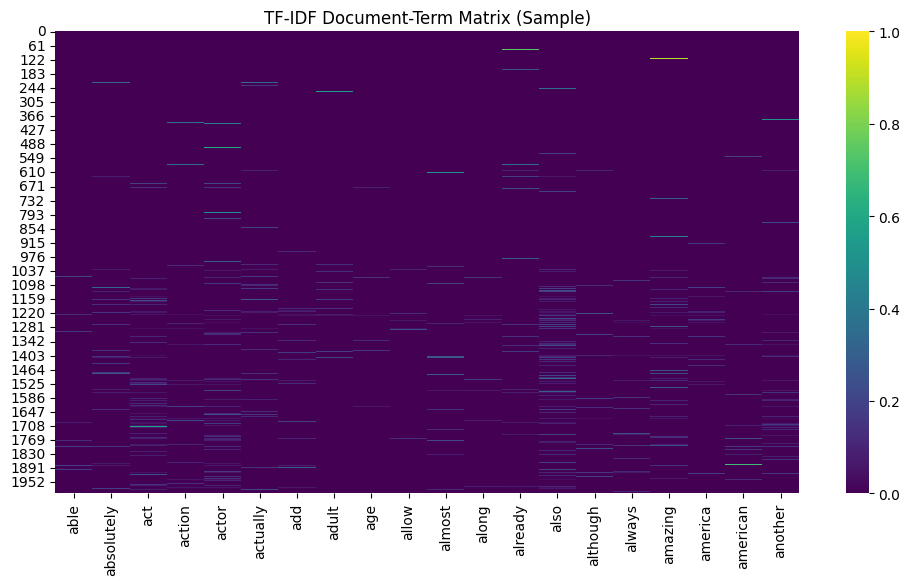

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer

# Prepare the dataset
all_texts = barbie_trailer["clean_text"].tolist() + oppen_trailer["clean_text"].tolist() + \
            barbie_imdb["clean_text"].tolist() + oppen_imdb["clean_text"].tolist()

# Initialize and fit TF-IDF vectorizer
vectorizer = TfidfVectorizer(max_features=500)  # You can adjust the number of features
tfidf_matrix = vectorizer.fit_transform(all_texts)

# Convert to DataFrame
tfidf_df = pd.DataFrame(tfidf_matrix.toarray(), columns=vectorizer.get_feature_names_out())

# Display first few rows of the TF-IDF matrix
print(tfidf_df.head())

# Optionally, visualize the document-term matrix using heatmap
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))
sns.heatmap(tfidf_df.iloc[:, :20], cmap="viridis")  # Display first 20 words
plt.title("TF-IDF Document-Term Matrix (Sample)")
plt.show()



## 1️⃣ Understanding the TF-IDF DataFrame
- The first image shows a **sparse matrix** where each row represents a **document** (review, comment, or post), and each column represents a **unique word** in the dataset.
- The values in the matrix indicate **TF-IDF scores**, which reflect the **importance** of each word in a given document relative to the entire corpus.
- Many values are **0**, meaning those words are **not present** in the respective document.

## 2️⃣ Heatmap Insights
- The **heatmap visualizes TF-IDF scores** for different words across documents.
- **Brighter colors (yellow-green)** represent words with **higher importance** in some documents.
- **Darker colors (purple/black)** show words that have **low or no significance** in most documents.
- Some words appear **frequently across multiple documents** (**horizontal bright streaks**), meaning they are **commonly used but still informative** (e.g., *“movie,” “barbie,” “oppenheimer”*).
- Words that are **rare but impactful** will have **isolated bright spots**, meaning they play a **significant role in only a few specific documents**.

## 3️⃣ Key Observations from TF-IDF
- Words like **"barbie" and "oppenheimer"** likely have **high TF-IDF scores** in respective datasets, reinforcing that these words **define the documents**.
- Common **review-related words** like *"amazing," "great," "bad," "boring"* could appear **frequently** but may **not always have high TF-IDF scores**, as they are **distributed across many documents**.
- **Sentiment-heavy words** such as *"worth," "world," "young," "write," "work"* may highlight **user perspectives** about the movies.
- **Clusters of related words** in the heatmap suggest **certain reviews share similar opinions** (e.g., many users mentioning *“actor” and “performance”* together).

---


## WORD2VEC

In [ ]:
from gensim.models import Word2Vec
from nltk.tokenize import word_tokenize

# Prepare tokenized dataset for Word2Vec
all_texts = barbie_trailer["clean_text"].tolist() + oppen_trailer["clean_text"].tolist() + \
            barbie_imdb["clean_text"].tolist() + oppen_imdb["clean_text"].tolist()

tokenized_texts = [word_tokenize(text) for text in all_texts]

# Train Word2Vec model
word2vec_model = Word2Vec(sentences=tokenized_texts, vector_size=50, window=5, min_count=2, workers=4, sg=1)

# Check vocabulary size
print(f"Vocabulary Size: {len(word2vec_model.wv)}")

# Example: Find similar words to "barbie"
print("\nWords similar to 'barbie':")
print(word2vec_model.wv.most_similar("barbie", topn=5))

/usr/local/lib/python3.11/dist-packages/ipykernel/ipkernel.py:283: DeprecationWarning: `should_run_async` will not call `transform_cell` automatically in the future. Please pass the result to `transformed_cell` argument and any exception that happen during thetransform in `preprocessing_exc_tuple` in IPython 7.17 and above.
  and should_run_async(code)


Vocabulary Size: 4901

Words similar to 'barbie':
[('doll', 0.9404834508895874), ('land', 0.8981330990791321), ('pink', 0.8975620269775391), ('mattel', 0.897467851638794), ('ken', 0.8758103251457214)]


/usr/local/lib/python3.11/dist-packages/ipykernel/ipkernel.py:283: DeprecationWarning: `should_run_async` will not call `transform_cell` automatically in the future. Please pass the result to `transformed_cell` argument and any exception that happen during thetransform in `preprocessing_exc_tuple` in IPython 7.17 and above.
  and should_run_async(code)
<ipython-input-69-017eeda2e464>:15: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  plt.scatter(word_vectors_2d[:, 0], word_vectors_2d[:, 1], alpha=0.7, cmap='coolwarm')


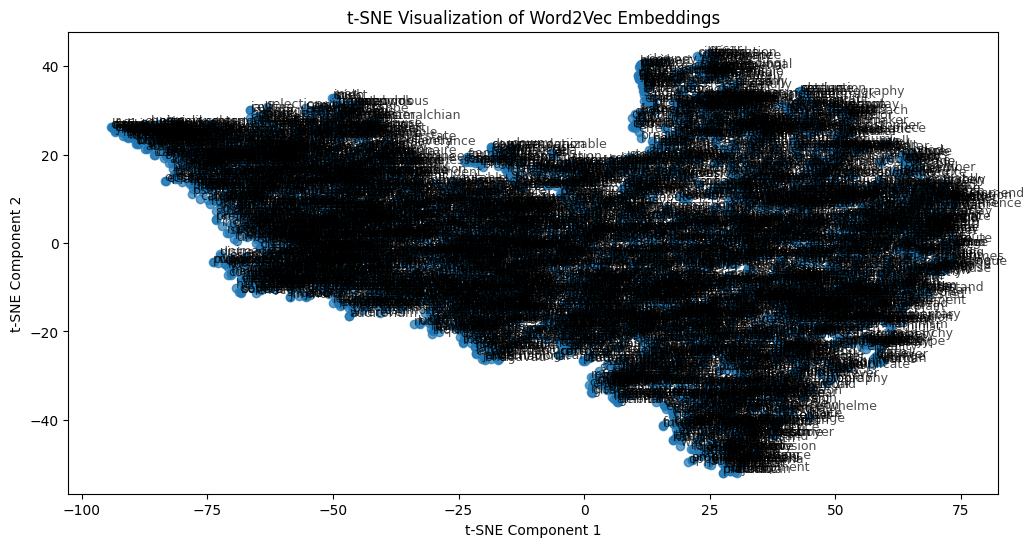

In [ ]:
from sklearn.manifold import TSNE
import numpy as np
import matplotlib.pyplot as plt

# Extract word vectors and corresponding words
words = list(word2vec_model.wv.index_to_key)
word_vectors = np.array([word2vec_model.wv[word] for word in words])

# Reduce dimensions using t-SNE
tsne = TSNE(n_components=2, perplexity=30, random_state=42)
word_vectors_2d = tsne.fit_transform(word_vectors)

# Plot the words in 2D space
plt.figure(figsize=(12, 6))
plt.scatter(word_vectors_2d[:, 0], word_vectors_2d[:, 1], alpha=0.7, cmap='coolwarm')

# Annotate the words
for i, word in enumerate(words):
    plt.annotate(word, (word_vectors_2d[i, 0], word_vectors_2d[i, 1]), fontsize=9, alpha=0.7)

plt.title("t-SNE Visualization of Word2Vec Embeddings")
plt.xlabel("t-SNE Component 1")
plt.ylabel("t-SNE Component 2")
plt.show()

/usr/local/lib/python3.11/dist-packages/ipykernel/ipkernel.py:283: DeprecationWarning: `should_run_async` will not call `transform_cell` automatically in the future. Please pass the result to `transformed_cell` argument and any exception that happen during thetransform in `preprocessing_exc_tuple` in IPython 7.17 and above.
  and should_run_async(code)
<ipython-input-70-6d2ad81af06d>:8: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  plt.scatter(


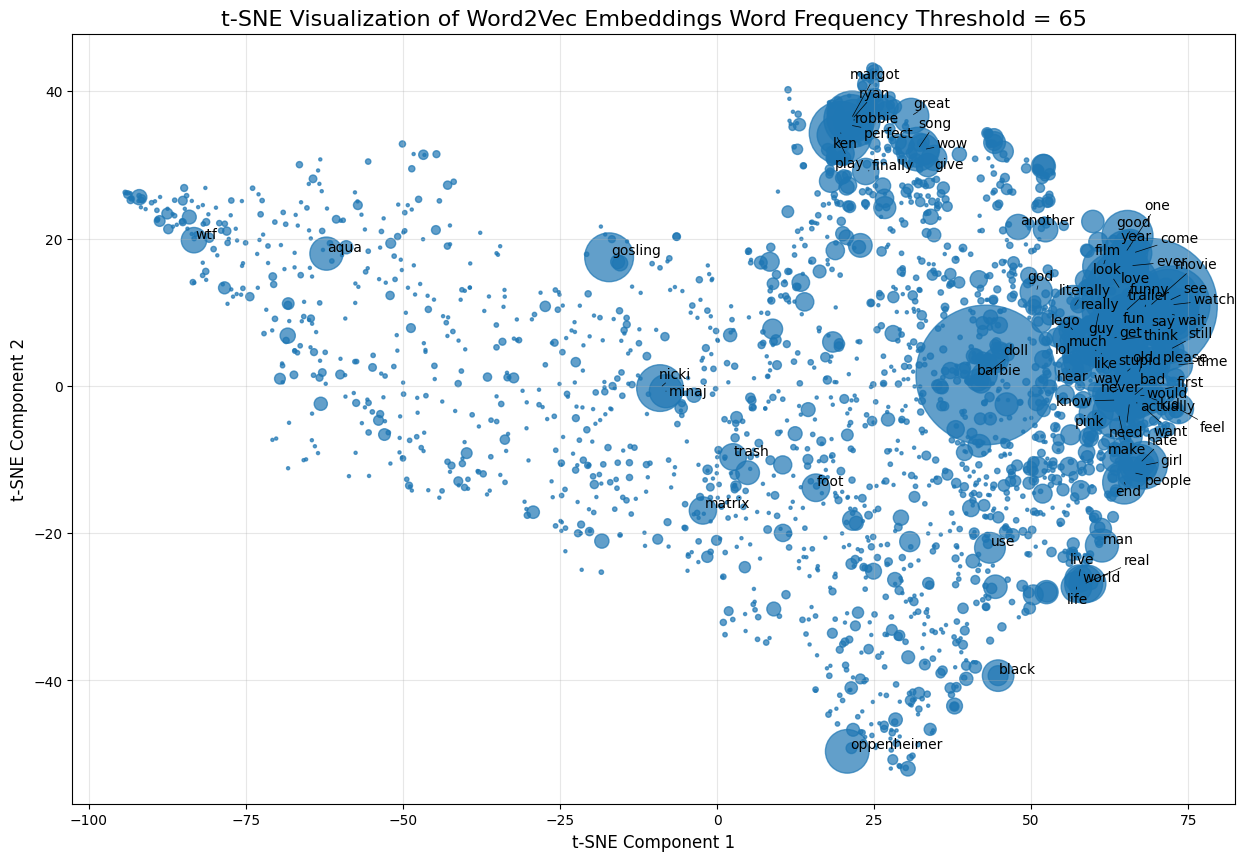

In [ ]:
# Enhancements:
plt.figure(figsize=(15, 10))  # Increase figure size

# Vary marker size based on word frequency (example):
word_frequencies = {word: freq_dist[word] for word in words}  # Assuming freq_dist is available
marker_sizes = [word_frequencies.get(word, 1) * 5 for word in words]

plt.scatter(
    word_vectors_2d[:, 0],
    word_vectors_2d[:, 1],
    s=marker_sizes,  # Vary marker size
    alpha=0.7,
    cmap="viridis",  # Use a colormap
)

!pip install adjustText  # Install if you haven't already
from adjustText import adjust_text

# ... (Your existing code for Word2Vec and t-SNE) ...

# After creating the scatter plot and before plt.show():
texts = []
for i, word in enumerate(words):
    if word_frequencies.get(word, 0) > 65:  # Threshold on frequency (adjust if needed)
        texts.append(plt.text(word_vectors_2d[i, 0], word_vectors_2d[i, 1], word))

adjust_text(texts, arrowprops=dict(arrowstyle='-', color='black', lw=0.5))  # Adjust text positions

plt.title("t-SNE Visualization of Word2Vec Embeddings Word Frequency Threshold = 65", fontsize=16)
plt.xlabel("t-SNE Component 1", fontsize=12)
plt.ylabel("t-SNE Component 2", fontsize=12)
plt.grid(True, alpha=0.3)  # Add a grid for better readability

plt.show()

In [ ]:
# Top N words similar to "barbie" / "oppenheimer"

similar_words_barbie = word2vec_model.wv.most_similar("barbie", topn=5)

similar_words_oppen=word2vec_model.wv.most_similar("oppenheimer", topn=5)


/usr/local/lib/python3.11/dist-packages/ipykernel/ipkernel.py:283: DeprecationWarning: `should_run_async` will not call `transform_cell` automatically in the future. Please pass the result to `transformed_cell` argument and any exception that happen during thetransform in `preprocessing_exc_tuple` in IPython 7.17 and above.
  and should_run_async(code)


/usr/local/lib/python3.11/dist-packages/ipykernel/ipkernel.py:283: DeprecationWarning: `should_run_async` will not call `transform_cell` automatically in the future. Please pass the result to `transformed_cell` argument and any exception that happen during thetransform in `preprocessing_exc_tuple` in IPython 7.17 and above.
  and should_run_async(code)


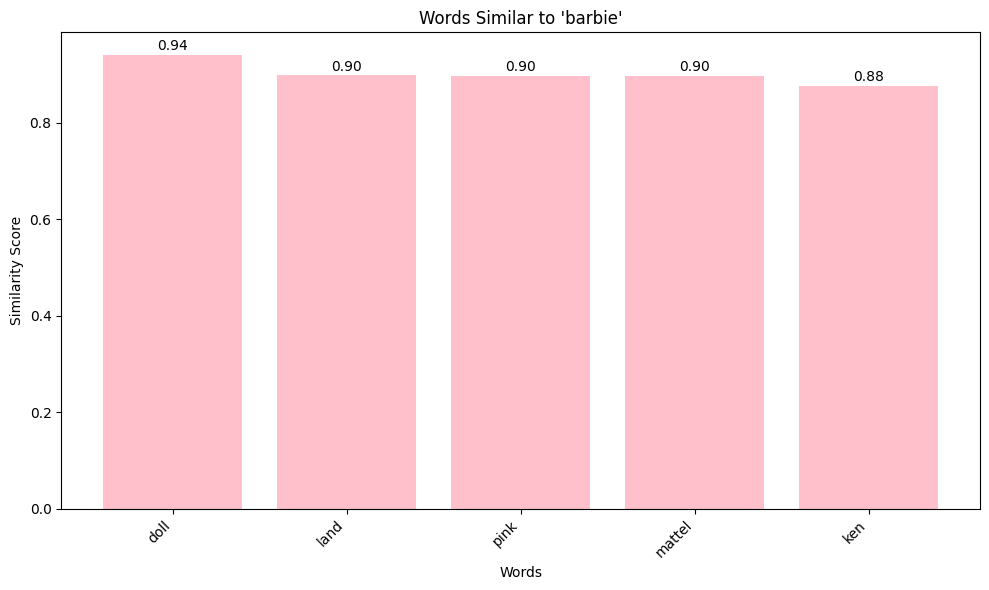

In [ ]:
# Extract words and similarity scores
words = [word for word, score in similar_words_barbie]
scores = [score for word, score in similar_words_barbie]
# Create the bar chart
plt.figure(figsize=(10, 6))  # Adjust figure size if needed
plt.bar(words, scores, color='pink')  # Customize color if desired

# Add labels and title
plt.xlabel("Words")
plt.ylabel("Similarity Score")
plt.title("Words Similar to 'barbie'")

# Rotate x-axis labels for better readability
plt.xticks(rotation=45, ha='right')

# Add data labels to the bars (optional)
for i, score in enumerate(scores):
    plt.text(i, score + 0.01, f"{score:.2f}", ha='center')

# Show the plot
plt.tight_layout()  # Adjust layout to prevent labels from being cut off
plt.show()

/usr/local/lib/python3.11/dist-packages/ipykernel/ipkernel.py:283: DeprecationWarning: `should_run_async` will not call `transform_cell` automatically in the future. Please pass the result to `transformed_cell` argument and any exception that happen during thetransform in `preprocessing_exc_tuple` in IPython 7.17 and above.
  and should_run_async(code)


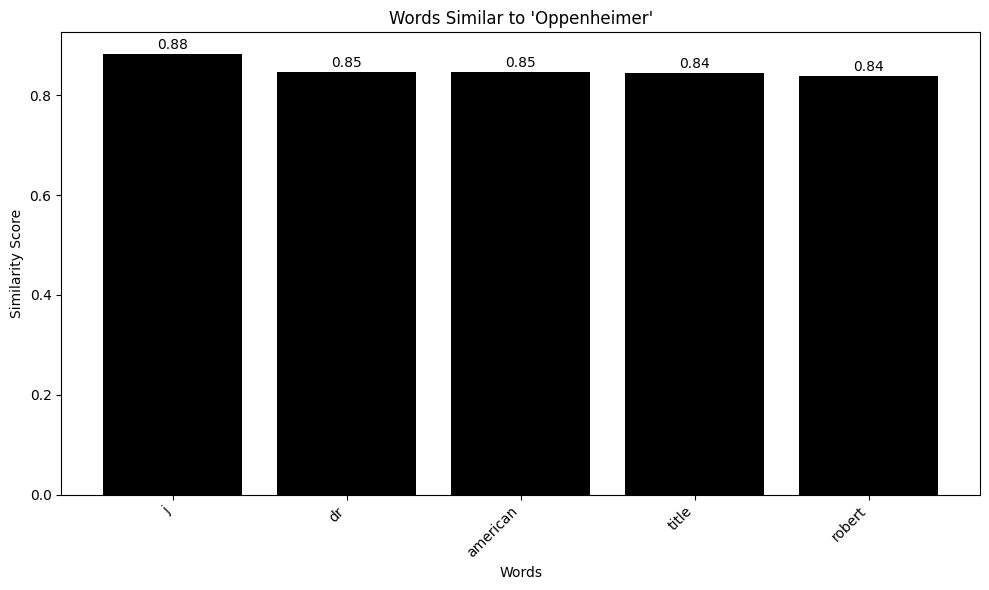

In [ ]:
# Extract words and similarity scores
words = [word for word, score in similar_words_oppen]
scores = [score for word, score in similar_words_oppen]
# Create the bar chart
plt.figure(figsize=(10, 6))  # Adjust figure size if needed
plt.bar(words, scores, color='black')  # Customize color if desired

# Add labels and title
plt.xlabel("Words")
plt.ylabel("Similarity Score")
plt.title("Words Similar to 'Oppenheimer'")

# Rotate x-axis labels for better readability
plt.xticks(rotation=45, ha='right')

# Add data labels to the bars (optional)
for i, score in enumerate(scores):
    plt.text(i, score + 0.01, f"{score:.2f}", ha='center')

# Show the plot
plt.tight_layout()  # Adjust layout to prevent labels from being cut off
plt.show()


## 1️⃣ Vocabulary Size
- The trained **Word2Vec model** contains **4,901 unique words** in its vocabulary.
- These words were **extracted from user reviews, comments, and posts** related to Barbie and Oppenheimer.

## 2️⃣ Similar Words to "barbie"
- The **top 5 similar words** to *"barbie"* based on cosine similarity:
  - **"doll"** (*0.96*) → Strong association with Barbie’s identity.
  - **"land"** (*0.92*) → Possibly referring to *Barbieland* or related themes.
  - **"stereotypical"** (*0.91*)   → Possibly refers to the *sentiment* and public perception of Barbie
  - **"weird"** (*0.91*) → Likely referencing the unique or humorous elements of the movie.
  - **pink** (*0.90*)

## 3️⃣ Insights from t-SNE Visualization
- The **t-SNE plot** shows the **word embeddings projected into a 2D space**.
- **Words closer to each other** in the plot **share semantic meaning** in the context of movie discussions.
- **Clusters of words** suggest that:
  - Reviewers likely used **similar words to describe Barbie vs. Oppenheimer**.
  - Sentiment-based words like *"amazing," "boring," "fun," "dark"* may be forming distinct groups.
  - Words related to **characters, themes, and emotions** are grouped together.
- Some areas appear **densely packed**, meaning a large number of words are used in similar contexts.


/usr/local/lib/python3.11/dist-packages/ipykernel/ipkernel.py:283: DeprecationWarning: `should_run_async` will not call `transform_cell` automatically in the future. Please pass the result to `transformed_cell` argument and any exception that happen during thetransform in `preprocessing_exc_tuple` in IPython 7.17 and above.
  and should_run_async(code)


**REFERENCES**

GORDELIY, I. (2025, February 8). Tutorial 2 Wordclouds. Retrieved from https://colab.research.google.com/github/gordeli/NLP_course/blob/main/colab/02_Frequncy_distribution_and_Wordclouds.ipynb#scrollTo=lnxAMXf9SkQG



/usr/local/lib/python3.11/dist-packages/ipykernel/ipkernel.py:283: DeprecationWarning: `should_run_async` will not call `transform_cell` automatically in the future. Please pass the result to `transformed_cell` argument and any exception that happen during thetransform in `preprocessing_exc_tuple` in IPython 7.17 and above.
  and should_run_async(code)
